# Battery Dataset Analysis & Validated Unified Dataset Builder

**Purpose:** perform EDA on NASA, CALCE, and Mobile2Mobile, then export a genuine cycle-level `data/unified.parquet` containing **all usable NASA and CALCE cells only**. Mobile2Mobile is analyzed but excluded from the supervised export because its Android telemetry does not provide an independently measured discharge-capacity label.

## Important corrections versus the previous notebook

- **NASA:** capacity is read from the official `cycle -> data -> Capacity` discharge field (Ah), and cycles that do not look like completed discharges are rejected before the SOH reference is selected.
- **CALCE:** only point-by-point `Channel_*` sheets are used for extraction. `Info` and `Statistics_*` sheets are retained for EDA/schema review, but are never treated as raw discharge records. CALCE discharge capacity is reconstructed by integrating the magnitude of negative discharge current over `Test_Time(s)`; the cumulative capacity counter is used only as an independent cross-check, never as a raw per-cycle capacity.
- Duplicate NASA battery files are resolved by content hash. Conflicting duplicate files stop the export.
- CALCE cycle indices are scoped to their session files, then cycles are ordered by recorded timestamp. Repeated / overlapping session cycles are detected instead of being silently dropped by a reused cycle index.
- SOH is consistently defined as **rated-capacity SOH using each cell's published nominal rating**:

\[
SOH_i(\%)=100\times\frac{Q_{i,\mathrm{discharge}}}{Q_{\mathrm{nominal}}}
\]

This is rated-capacity SOH. NASA's dataset catalogue gives a 2.0 Ah rated capacity; CALCE publishes 1.10 Ah for CS2 and 1.35 Ah for CX2. Capacity-derived columns and elapsed-time/sample-count proxies are explicitly excluded from model predictors.

**Fail-closed policy:** the notebook will not overwrite `unified.parquet` unless the expected 34 NASA + 13 CALCE cells are present, every exported cell has valid cycles, the capacity/voltage audits are plausible, duplicate conflicts are absent, and the Parquet round-trip checks pass. If a source file has an unexpected layout, the notebook reports it and stops rather than guessing.

## Source-specific reference notes

- NASA's documented MAT structure identifies `cycle.type`, `cycle.data.Capacity` (Ah), measured voltage/current/temperature, and states the discharge capacity is for discharge to 2.7 V. See the [NASA battery dataset catalogue](https://catalog.data.gov/dataset/li-ion-battery-aging-datasets).
- CALCE publishes a 1.10 Ah rating for CS2 and 1.35 Ah for CX2; the selected Arbin Excel files contain point-wise channel data. See [CALCE battery data](https://calce.umd.edu/data).

**Mobile2Mobile EDA outputs:** full Parquet file/schema inventory, streaming numeric summaries, categorical frequency tables, distinct-device inventory, timestamp coverage, scan-error log, bounded random row sample, and signal distribution/relationship plots. These outputs are saved under `data/analysis_outputs/` and are not part of `unified.parquet`.

## 0. Install dependencies

In [1]:
%pip install -q numpy pandas scipy openpyxl xlrd pyarrow h5py mat73 matplotlib seaborn tqdm

Note: you may need to restart the kernel to use updated packages.


## 1. Imports, settings, and project paths

In [2]:
from pathlib import Path
from collections import Counter
from datetime import datetime, timedelta
import hashlib, json, math, re, warnings
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
from scipy.io import loadmat
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

SEED = 42
np.random.seed(SEED)
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 180)

CWD = Path.cwd().resolve()
possible_roots = [CWD, CWD / "data", CWD.parent / "data"]
DATA_DIR = next((p for p in possible_roots
                 if (p / "nasa").is_dir() and (p / "calce").is_dir()
                 and (p / "mobile2mobile").is_dir()), None)
if DATA_DIR is None:
    raise FileNotFoundError(
        f"Could not locate data/nasa, data/calce and data/mobile2mobile. Current directory: {CWD}"
    )

NASA_DIR = DATA_DIR / "nasa"
CALCE_DIR = DATA_DIR / "calce"
MOBILE_DIR = DATA_DIR / "mobile2mobile"
MOBILE_SELECTED_DIR = MOBILE_DIR / "selected_data"
MOBILE_SCAN_DIR = MOBILE_DIR
OUTPUT_PARQUET = DATA_DIR / "unified.parquet"
AUDIT_DIR = DATA_DIR / "analysis_outputs"
AUDIT_DIR.mkdir(parents=True, exist_ok=True)

EXPECTED_NASA_CELLS = 34
EXPECTED_CALCE_CELLS = 13
EXPECTED_TOTAL_CELLS = EXPECTED_NASA_CELLS + EXPECTED_CALCE_CELLS

NASA_NOMINAL_AH = 2.00
CALCE_NOMINAL_AH = {"CS2": 1.10, "CX2": 1.35}
NASA_MIN_CAPACITY_AH = 0.20
NASA_MAX_CAPACITY_AH = 2.60
NASA_FULL_DISCHARGE_VMAX = 3.15
CALCE_FULL_DISCHARGE_VMAX = 3.05
CALCE_CURRENT_THRESHOLD_A = 0.01

print("Project data directory:", DATA_DIR)
print("Output file (written only after all gates pass):", OUTPUT_PARQUET)
print("Expected cells:", EXPECTED_NASA_CELLS, "NASA +", EXPECTED_CALCE_CELLS, "CALCE")

Project data directory: /home/raj/Documents/Projects/PBL/data
Output file (written only after all gates pass): /home/raj/Documents/Projects/PBL/data/unified.parquet
Expected cells: 34 NASA + 13 CALCE


## 2. Full file inventory across all three datasets

In [3]:
SOURCE_DIRS = {"NASA": NASA_DIR, "CALCE": CALCE_DIR, "MOBILE2MOBILE": MOBILE_SCAN_DIR}
file_rows = []
for source, root in SOURCE_DIRS.items():
    for path in sorted(root.rglob("*")):
        if path.is_file():
            file_rows.append({
                "source": source,
                "relative_path": str(path.relative_to(DATA_DIR)),
                "extension": path.suffix.lower(),
                "size_MB": path.stat().st_size / (1024**2),
            })
file_inventory = pd.DataFrame(file_rows)
if file_inventory.empty:
    raise RuntimeError("No source files found.")
display(file_inventory.groupby(["source", "extension"]).agg(
    files=("relative_path", "count"), size_MB=("size_MB", "sum")
).reset_index())
file_inventory.to_csv(AUDIT_DIR / "file_inventory.csv", index=False)
display(file_inventory.groupby("source").agg(files=("relative_path", "count"), total_MB=("size_MB", "sum")))

,source,extension,files,size_MB
0,CALCE,.txt,2,2.186768
1,CALCE,.xlsx,86,178.752165
2,MOBILE2MOBILE,.parquet,28,193.081052
3,NASA,.mat,38,199.934372
4,NASA,.txt,10,0.024047


,files,total_MB
source,,
CALCE,88,180.938932
MOBILE2MOBILE,28,193.081052
NASA,48,199.958419


## 3. Mobile2Mobile EDA — full-dataset audit, streaming statistics, device diversity and signal relationships

Mobile2Mobile is explored **separately and comprehensively**, but it is not exported into the supervised NASA–CALCE SOH dataset. This section:

- inventories every Mobile2Mobile Parquet file and schema;
- scans selected columns from **all files in streaming batches** (no full dataset loaded into RAM);
- computes missingness, numeric summaries, categorical frequencies, unique-device counts and timestamp coverage;
- creates a bounded random sample for plots and cross-signal relationships;
- audits `health`, SOC and charge-counter semantics without pretending they are measured SOH labels.

The scan can take time on the full 6–7 GB corpus, but keeps memory bounded. Set `MOBILE_FULL_SCAN=False` only for a quick exploratory run; the inventory still covers every file.

In [4]:
MOBILE_FULL_SCAN = True
MOBILE_BATCH_SIZE = 100_000
MOBILE_SAMPLE_PER_BATCH = 30
MOBILE_RANDOM_SEED = 42
MOBILE_TOP_K = 30

mobile_files = sorted(MOBILE_SCAN_DIR.rglob("*.parquet"))
if not mobile_files:
    raise FileNotFoundError(f"No Mobile2Mobile Parquet files found under {MOBILE_SCAN_DIR}")

MOBILE_ALIASES = {
    "device_id": ["cell_id", "device_id", "battery_id"],
    "timestamp": ["timestamp", "time", "datetime", "recorded_at"],
    "manufacturer": ["manufacturer", "brand", "device_manufacturer"],
    "model": ["model", "device_model"],
    "battery_technology": ["battery_technology", "technology", "chemistry"],
    "os": ["os", "operating_system", "platform"],
    "health": ["health", "battery_health"],
    "status": ["status", "charging_status", "charge_status"],
    "kind": ["kind", "record_kind", "event_type"],
    "voltage_raw": ["voltage", "voltage_v", "battery_voltage"],
    "current_raw": ["current", "current_a", "current_ma", "battery_current"],
    "temperature_raw": ["temp", "temperature", "temperature_c", "battery_temperature"],
    "soc_pct": ["soc", "state_of_charge", "battery_level"],
    "charge_counter_raw": ["charge_counter", "chargecounter", "charge_counter_uah"],
    "nominal_capacity_raw": ["nominal_capacity", "nominalcapacity", "design_capacity"],
    "cycle_count_raw": ["cycle_count", "cyclecount", "charge_cycles"],
}

def _mobile_norm(name):
    return re.sub(r"[^a-z0-9]+", "", str(name).lower())

def _mobile_resolve_columns(schema_names):
    norm_to_actual = {_mobile_norm(c): c for c in schema_names}
    resolved = {}
    for canonical, aliases in MOBILE_ALIASES.items():
        for alias in aliases:
            actual = norm_to_actual.get(_mobile_norm(alias))
            if actual is not None:
                resolved[canonical] = actual
                break
    return resolved

mobile_file_rows = []
mobile_schema_fingerprints = Counter()
mobile_scan_errors = []
for p in mobile_files:
    try:
        pf = pq.ParquetFile(p)
        names = pf.schema_arrow.names
        fingerprint = "|".join(sorted(names))
        mobile_schema_fingerprints[fingerprint] += 1
        mobile_file_rows.append({
            "file": str(p.relative_to(DATA_DIR)),
            "rows": pf.metadata.num_rows,
            "row_groups": pf.metadata.num_row_groups,
            "size_MB": p.stat().st_size / (1024**2),
            "columns": " | ".join(names),
            "schema_fingerprint": hashlib.sha1(fingerprint.encode()).hexdigest()[:12],
        })
    except Exception as exc:
        mobile_scan_errors.append({"file": str(p), "stage": "inventory", "error": repr(exc)})

mobile_inventory = pd.DataFrame(mobile_file_rows)
if mobile_inventory.empty:
    raise RuntimeError("No Mobile2Mobile Parquet files could be inspected.")
display(mobile_inventory.head(30))
display(mobile_inventory.groupby("schema_fingerprint").agg(
    files=("file", "count"), rows=("rows", "sum"), size_MB=("size_MB", "sum")
).reset_index())
print("Files:", len(mobile_inventory),
      "| Total rows recorded in Parquet metadata:", f"{int(mobile_inventory['rows'].sum()):,}",
      "| Total size (MB):", round(mobile_inventory["size_MB"].sum(), 2))
mobile_inventory.to_csv(AUDIT_DIR / "mobile2mobile_inventory.csv", index=False)

mobile_numeric_stats = {
    k: {"count": 0, "missing": 0, "sum": 0.0, "sum_sq": 0.0,
        "min": np.inf, "max": -np.inf}
    for k in ["voltage_raw", "current_raw", "temperature_raw", "soc_pct",
              "charge_counter_raw", "nominal_capacity_raw", "cycle_count_raw"]
}
mobile_categorical_counts = {
    k: Counter() for k in ["manufacturer", "model", "battery_technology",
                           "os", "health", "status", "kind"]
}
mobile_unique_values = {k: set() for k in
                        ["device_id", "manufacturer", "model", "battery_technology", "os"]}
mobile_device_rows = Counter()
mobile_device_meta = {}
mobile_time_min = None
mobile_time_max = None
mobile_total_rows_scanned = 0
mobile_total_missing_device_id = 0
mobile_sample_parts = []
sample_rng = np.random.default_rng(MOBILE_RANDOM_SEED)

def _mobile_update_timestamp(series):
    global mobile_time_min, mobile_time_max
    if series is None:
        return
    try:
        if pd.api.types.is_numeric_dtype(series):
            vals = pd.to_numeric(series, errors="coerce").dropna()
            if vals.empty:
                return
            median_abs = float(vals.abs().median())
            if median_abs > 1e17:
                unit = "ns"
            elif median_abs > 1e14:
                unit = "us"
            elif median_abs > 1e11:
                unit = "ms"
            elif median_abs > 1e8:
                unit = "s"
            else:
                return
            parsed = pd.to_datetime(vals, unit=unit, errors="coerce", utc=True)
        else:
            parsed = pd.to_datetime(series, errors="coerce", utc=True)
        parsed = parsed.dropna()
        if not parsed.empty:
            lo, hi = parsed.min(), parsed.max()
            mobile_time_min = lo if mobile_time_min is None else min(mobile_time_min, lo)
            mobile_time_max = hi if mobile_time_max is None else max(mobile_time_max, hi)
    except Exception:
        pass

files_to_scan = mobile_files if MOBILE_FULL_SCAN else mobile_files[:min(100, len(mobile_files))]
print(f"Streaming scan: {len(files_to_scan)} / {len(mobile_files)} files; "
      f"batch size={MOBILE_BATCH_SIZE:,}")

for file_no, p in enumerate(files_to_scan, 1):
    try:
        pf = pq.ParquetFile(p)
        resolved = _mobile_resolve_columns(pf.schema_arrow.names)
        physical_cols = list(dict.fromkeys(resolved.values()))
        if not physical_cols:
            mobile_scan_errors.append({"file": str(p), "stage": "column_resolution",
                                       "error": "No recognized Mobile2Mobile columns"})
            continue

        for batch in pf.iter_batches(batch_size=MOBILE_BATCH_SIZE, columns=physical_cols):
            raw = batch.to_pandas()
            mobile_total_rows_scanned += len(raw)

            chunk = pd.DataFrame(index=raw.index)
            for canonical, actual in resolved.items():
                chunk[canonical] = raw[actual]

            if "device_id" in chunk:
                ids = chunk["device_id"].astype("string").str.strip()
                mobile_total_missing_device_id += int(ids.isna().sum() + ids.eq("").sum())
                valid_ids = ids[ids.notna() & ids.ne("")]
                mobile_unique_values["device_id"].update(valid_ids.unique().tolist())
                mobile_device_rows.update(valid_ids.value_counts().to_dict())

                meta_cols = [c for c in ["manufacturer", "model", "battery_technology", "os"] if c in chunk]
                if meta_cols:
                    meta = chunk[["device_id"] + meta_cols].copy()
                    for did, g in meta.groupby("device_id", dropna=True):
                        key = str(did)
                        record = mobile_device_meta.setdefault(key, {})
                        for c in meta_cols:
                            vals = g[c].dropna().astype(str)
                            if len(vals):
                                record.setdefault(c, Counter()).update(vals.value_counts().to_dict())

            for col in mobile_numeric_stats:
                if col not in chunk:
                    continue
                st = mobile_numeric_stats[col]
                vals = pd.to_numeric(chunk[col], errors="coerce").to_numpy(dtype=float)
                finite = vals[np.isfinite(vals)]
                st["missing"] += int(len(vals) - len(finite))
                if finite.size:
                    st["count"] += int(finite.size)
                    st["sum"] += float(finite.sum(dtype=np.float64))
                    st["sum_sq"] += float(np.square(finite, dtype=np.float64).sum(dtype=np.float64))
                    st["min"] = min(st["min"], float(finite.min()))
                    st["max"] = max(st["max"], float(finite.max()))

            for col in mobile_categorical_counts:
                if col in chunk:
                    s = chunk[col].dropna().astype(str).str.strip()
                    s = s[s.ne("")]
                    mobile_categorical_counts[col].update(s.value_counts().to_dict())
                    if col in mobile_unique_values:
                        mobile_unique_values[col].update(s.unique().tolist())

            if "timestamp" in chunk:
                _mobile_update_timestamp(chunk["timestamp"])

            if MOBILE_SAMPLE_PER_BATCH > 0 and len(chunk):
                n_take = min(MOBILE_SAMPLE_PER_BATCH, len(chunk))
                idx = sample_rng.choice(len(chunk), size=n_take, replace=False)
                mobile_sample_parts.append(chunk.iloc[idx].copy())

    except Exception as exc:
        mobile_scan_errors.append({"file": str(p), "stage": "stream_scan", "error": repr(exc)})

    if file_no % 25 == 0 or file_no == len(files_to_scan):
        print(f"Scanned {file_no}/{len(files_to_scan)} files; "
              f"{mobile_total_rows_scanned:,} rows; "
              f"{len(mobile_unique_values['device_id']):,} distinct device IDs so far")

mobile_sample_df = pd.concat(mobile_sample_parts, ignore_index=True) if mobile_sample_parts else pd.DataFrame()

numeric_rows = []
for col, st in mobile_numeric_stats.items():
    count = st["count"]
    if count:
        mean = st["sum"] / count
        variance = max(0.0, st["sum_sq"] / count - mean**2)
        numeric_rows.append({
            "field": col, "valid_values": count, "missing_values": st["missing"],
            "missing_pct": 100 * st["missing"] / max(1, count + st["missing"]),
            "mean_raw_units": mean, "std_raw_units": np.sqrt(variance),
            "min_raw_units": st["min"], "max_raw_units": st["max"],
        })
    else:
        numeric_rows.append({"field": col, "valid_values": 0, "missing_values": st["missing"]})
mobile_numeric_summary = pd.DataFrame(numeric_rows)
display(mobile_numeric_summary)
mobile_numeric_summary.to_csv(AUDIT_DIR / "mobile2mobile_numeric_summary.csv", index=False)

cat_rows = []
for col, counts in mobile_categorical_counts.items():
    for value, n in counts.most_common(MOBILE_TOP_K):
        cat_rows.append({"field": col, "value": value, "count": int(n),
                         "share_of_nonempty_pct": 100 * n / max(1, sum(counts.values()))})
mobile_categorical_summary = pd.DataFrame(cat_rows)
display(mobile_categorical_summary)
mobile_categorical_summary.to_csv(AUDIT_DIR / "mobile2mobile_categorical_top_values.csv", index=False)

print("Total scanned rows:", f"{mobile_total_rows_scanned:,}")
print("Unique device IDs:", len(mobile_unique_values["device_id"]))
print("Rows missing device ID:", f"{mobile_total_missing_device_id:,}")
print("Timestamp coverage:", mobile_time_min, "to", mobile_time_max)
print("Random EDA sample shape:", mobile_sample_df.shape)
print("Errors:", len(mobile_scan_errors))
if mobile_scan_errors:
    display(pd.DataFrame(mobile_scan_errors).head(30))
    pd.DataFrame(mobile_scan_errors).to_csv(AUDIT_DIR / "mobile2mobile_scan_errors.csv", index=False)

device_rows = []
for did, n in mobile_device_rows.items():
    rec = {"device_id": did, "rows": int(n)}
    metadata = mobile_device_meta.get(did, {})
    for col, counter in metadata.items():
        rec[col] = counter.most_common(1)[0][0] if counter else None
    device_rows.append(rec)
mobile_device_inventory = pd.DataFrame(device_rows).sort_values("rows", ascending=False) if device_rows else pd.DataFrame()
display(mobile_device_inventory.head(50))
mobile_device_inventory.to_csv(AUDIT_DIR / "mobile2mobile_device_inventory.csv", index=False)

if not mobile_sample_df.empty:
    mobile_sample_df.to_parquet(AUDIT_DIR / "mobile2mobile_random_eda_sample.parquet",
                                index=False, compression="zstd")

,file,rows,row_groups,size_MB,columns,schema_fingerprint
0,mobile2mobile/selected_data/038724c3ec382abe1e...,1024629,132,11.101226,cell_id | timestamp | battery_technology | man...,1f47fe3f0bf6
1,mobile2mobile/selected_data/13d07b174a2fad9423...,273035,35,2.788984,cell_id | timestamp | battery_technology | man...,1f47fe3f0bf6
2,mobile2mobile/selected_data/1c549b8e0abac7193b...,3750,5,0.088110,cell_id | timestamp | battery_technology | man...,1f47fe3f0bf6
3,mobile2mobile/selected_data/204a90fb0bb4ea8b88...,1225956,157,13.366133,cell_id | timestamp | battery_technology | man...,1f47fe3f0bf6
4,mobile2mobile/selected_data/390119b7903bf350b1...,1214927,157,13.669004,cell_id | timestamp | battery_technology | man...,1f47fe3f0bf6
5,mobile2mobile/selected_data/3b0708ec03aea8a59e...,1164476,151,12.879576,cell_id | timestamp | battery_technology | man...,1f47fe3f0bf6
6,mobile2mobile/selected_data/5743a4e5a5322b1691...,1139644,149,12.984632,cell_id | timestamp | battery_technology | man...,1f47fe3f0bf6
7,mobile2mobile/selected_data/59677e8386c3f04b24...,1219671,157,12.499219,cell_id | timestamp | battery_technology | man...,1f47fe3f0bf6
8,mobile2mobile/selected_data/5b8701da9702a9a6ed...,565287,71,5.213820,cell_id | timestamp | battery_technology | man...,1f47fe3f0bf6
9,mobile2mobile/selected_data/5ef060720c159ea2b2...,446549,59,5.127540,cell_id | timestamp | battery_technology | man...,1f47fe3f0bf6


,schema_fingerprint,files,rows,size_MB
0,1f47fe3f0bf6,28,18038756,193.081052


Files: 28 | Total rows recorded in Parquet metadata: 18,038,756 | Total size (MB): 193.08
Streaming scan: 28 / 28 files; batch size=100,000
Scanned 25/28 files; 15,296,725 rows; 25 distinct device IDs so far
Scanned 28/28 files; 18,038,756 rows; 28 distinct device IDs so far


,field,valid_values,missing_values,missing_pct,mean_raw_units,std_raw_units,min_raw_units,max_raw_units
0,voltage_raw,0,0,NaN,NaN,NaN,NaN,NaN
1,current_raw,18038458,298,0.001652,-0.034392,0.615027,-14.00,18.000
2,temperature_raw,0,0,NaN,NaN,NaN,NaN,NaN
3,soc_pct,18038756,0,0.000000,61.022994,26.294740,0.00,100.000
4,charge_counter_raw,18035579,3177,0.017612,2.514789,1.302353,0.00,5.000
5,nominal_capacity_raw,18038756,0,0.000000,4.891294,0.018470,4.86,4.905
6,cycle_count_raw,18038756,0,0.000000,66.811458,141.286171,0.00,534.000


,field,value,count,share_of_nonempty_pct
0,manufacturer,samsung,18038756,100.000000
1,model,SM-A356B,1261682,6.994285
2,model,SM-A127F,1246213,6.908531
3,model,SM-A166B,1225956,6.796234
4,model,SM-A156B,1224904,6.790402
...,...,...,...,...
64,status,3.0,14002834,77.626384
65,status,5.0,1498452,8.306848
66,status,2.0,1473466,8.168335
67,status,4.0,1064004,5.898433


Total scanned rows: 18,038,756
Unique device IDs: 28
Rows missing device ID: 0
Timestamp coverage: 2026-04-29 01:26:06.265000+00:00 to 2026-09-30 23:59:59.714000+00:00
Random EDA sample shape: (5880, 14)
Errors: 0


,device_id,rows,manufacturer,model,battery_technology,os
17,94be8152e70c10e3f5d2d2d1b1c8bf98,1261682,samsung,SM-A356B,Li-ion,samsung/a35xeea/a35x:16/BP2A.250605.031.A3/A35...
25,ec09dfd20bd0cc21ed53a55e8afb3c9b,1246213,samsung,SM-A127F,Li-ion,samsung/a12snseea/a12s:13/TP1A.220624.014/A127...
3,204a90fb0bb4ea8b883304470e7a1b19,1225956,samsung,SM-A166B,Li-ion,samsung/a16xeea/a16x:16/BP4A.251205.006/A166BX...
16,920e9054ae23d520426569623cc0bd20,1224904,samsung,SM-A156B,Li-ion,samsung/a15xeea/a15x:16/BP2A.250605.031.A3/A15...
7,59677e8386c3f04b2483cea00cbe5d72,1219671,samsung,SM-A057F,Li-ion,samsung/a05snndxx/a05s:15/AP3A.240905.015.A2/A...
4,390119b7903bf350b17adf11f5d14ce2,1214927,samsung,SM-A346B,Li-ion,samsung/a34xeea/a34x:16/BP2A.250605.031.A3/A34...
27,edc9dd9f4406fcff3786c7f1e3757a79,1212657,samsung,SM-A366B,Li-ion,samsung/a36xqnaeea/a36xq:16/BP4A.251205.006/A3...
5,3b0708ec03aea8a59edeb92d0dfb3eab,1164476,samsung,SM-A236B,Li-ion,samsung/a23xqnseea/a23xq:14/UP1A.231005.007/A2...
6,5743a4e5a5322b1691e86c58308dc4b4,1139644,samsung,SM-A137F,Li-ion,samsung/a13venseea/a13ve:14/UP1A.231005.007/A1...
15,8db535f0e09cb8814f3221a5597fbca6,1059847,samsung,SM-A346E,Li-ion,samsung/a34xdxx/a34x:16/BP2A.250605.031.A3/A34...


### Mobile2Mobile signal distributions and relationships

The following plots use the bounded random sample drawn during the streaming scan. They are descriptive only; no synthetic SOH target is constructed.

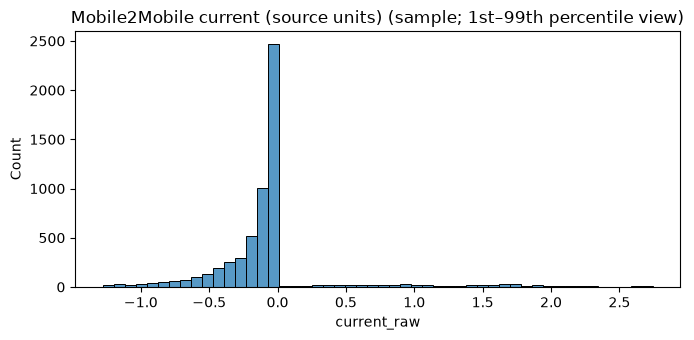

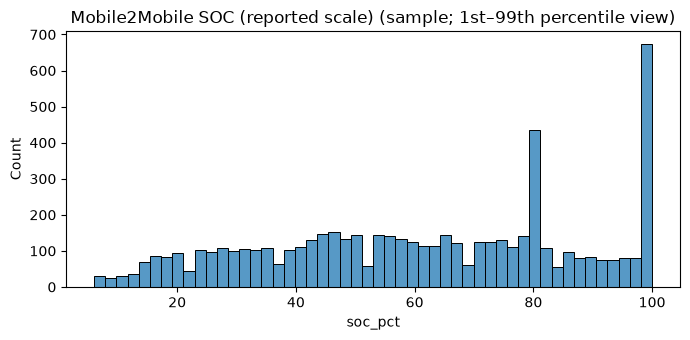

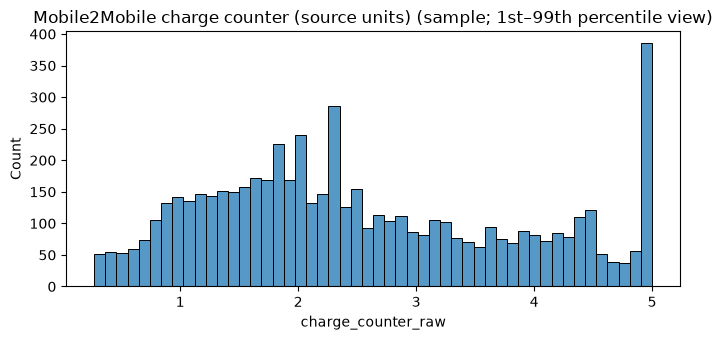

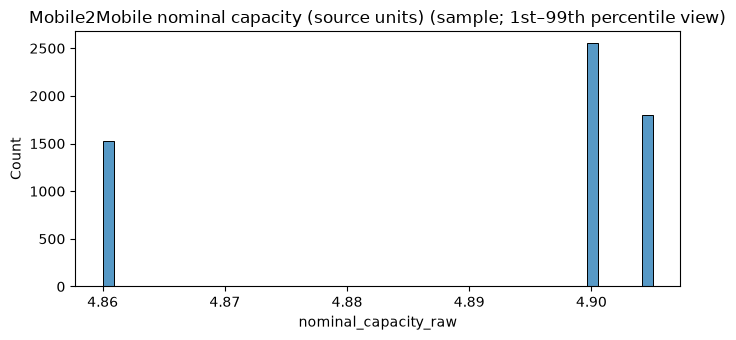

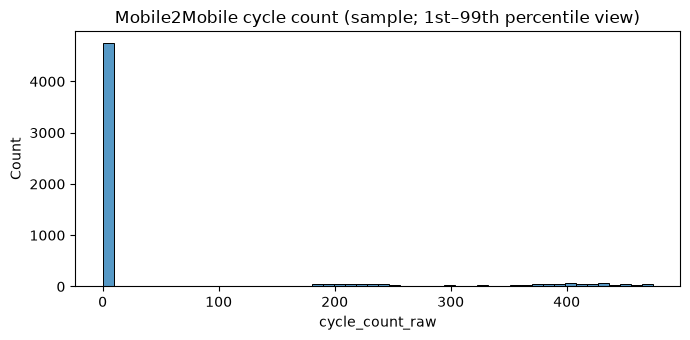

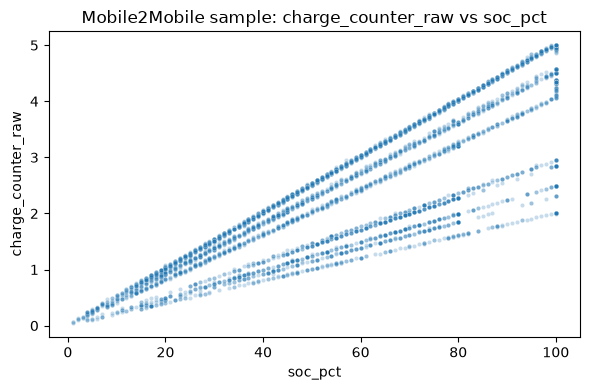

,sample_count
health,
2.0,5876
1.0,3
3.0,1


,sample_count
status,
3.0,4532
2.0,496
5.0,496
4.0,356


,sample_count
kind,
cycling,5880


,sample_count
battery_technology,
Li-ion,5880


Interpretation: Android health/status are operating-system telemetry categories; SOC is charge level, not SOH; charge_counter and nominal_capacity are device-reported telemetry and do not independently establish discharge capacity. Mobile2Mobile is therefore EDA-only in this supervised capacity-SOH experiment.


In [5]:
if mobile_sample_df.empty:
    print("No sample rows available for visual EDA.")
else:
    mobile_plot_specs = [
        ("voltage_raw", "Mobile2Mobile voltage (source units)"),
        ("current_raw", "Mobile2Mobile current (source units)"),
        ("temperature_raw", "Mobile2Mobile temperature (source units)"),
        ("soc_pct", "Mobile2Mobile SOC (reported scale)"),
        ("charge_counter_raw", "Mobile2Mobile charge counter (source units)"),
        ("nominal_capacity_raw", "Mobile2Mobile nominal capacity (source units)"),
        ("cycle_count_raw", "Mobile2Mobile cycle count"),
    ]
    for col, title in mobile_plot_specs:
        if col in mobile_sample_df and pd.to_numeric(mobile_sample_df[col], errors="coerce").notna().sum():
            vals = pd.to_numeric(mobile_sample_df[col], errors="coerce").dropna()
            lo, hi = vals.quantile([0.01, 0.99])
            vals = vals[(vals >= lo) & (vals <= hi)]
            plt.figure(figsize=(7, 3.5))
            sns.histplot(vals, bins=50)
            plt.title(title + " (sample; 1st–99th percentile view)")
            plt.xlabel(col)
            plt.tight_layout()
            plt.show()

    pair_candidates = [
        ("soc_pct", "voltage_raw"),
        ("soc_pct", "charge_counter_raw"),
        ("current_raw", "temperature_raw"),
        ("voltage_raw", "current_raw"),
    ]
    for x, y in pair_candidates:
        if x in mobile_sample_df and y in mobile_sample_df:
            xy = mobile_sample_df[[x, y]].apply(pd.to_numeric, errors="coerce").dropna()
            if len(xy) > 20:
                if len(xy) > 20_000:
                    xy = xy.sample(20_000, random_state=42)
                plt.figure(figsize=(6, 4))
                sns.scatterplot(data=xy, x=x, y=y, alpha=0.25, s=9)
                plt.title(f"Mobile2Mobile sample: {y} vs {x}")
                plt.tight_layout()
                plt.show()

    for col in ["health", "status", "kind", "battery_technology"]:
        if col in mobile_sample_df:
            display(mobile_sample_df[col].value_counts(dropna=False).head(25).rename_axis(col).to_frame("sample_count"))

print(
    "Interpretation: Android health/status are operating-system telemetry categories; "
    "SOC is charge level, not SOH; charge_counter and nominal_capacity are device-reported "
    "telemetry and do not independently establish discharge capacity. Mobile2Mobile is "
    "therefore EDA-only in this supervised capacity-SOH experiment."
)

## 4. NASA EDA — deduplicated MAT inventory and structure

In [6]:
nasa_mat_files = sorted(NASA_DIR.rglob("*.mat"))
if not nasa_mat_files:
    raise FileNotFoundError(f"No NASA MAT files under {NASA_DIR}")

def sha256_file(path, chunk_size=1024*1024):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while True:
            chunk = f.read(chunk_size)
            if not chunk: break
            h.update(chunk)
    return h.hexdigest()

by_stem = {}
for p in nasa_mat_files:
    by_stem.setdefault(p.stem.upper(), []).append(p)
nasa_canonical_files, nasa_duplicate_log, nasa_conflicts = [], [], []
for cell, paths in sorted(by_stem.items()):
    hashes = {p: sha256_file(p) for p in paths}
    unique_hashes = set(hashes.values())
    if len(unique_hashes) > 1:
        nasa_conflicts.append({"cell_id": cell, "files": [str(p) for p in paths], "hashes": list(unique_hashes)})
        continue
    chosen = sorted(paths, key=lambda p: (len(str(p)), str(p)))[0]
    nasa_canonical_files.append(chosen)
    for duplicate in paths:
        if duplicate != chosen:
            nasa_duplicate_log.append({"cell_id": cell, "kept": str(chosen.relative_to(DATA_DIR)),
                                       "duplicate": str(duplicate.relative_to(DATA_DIR)),
                                       "sha256": hashes[chosen]})

nasa_inventory = pd.DataFrame([{
    "cell_id": p.stem.upper(), "file": str(p.relative_to(DATA_DIR)),
    "size_MB": p.stat().st_size / (1024**2), "sha256": sha256_file(p)
} for p in nasa_canonical_files])
display(nasa_inventory)
print("Unique NASA cells:", nasa_inventory.cell_id.nunique())
print("Exact duplicate MAT files removed:", len(nasa_duplicate_log))
print("Conflicting duplicate groups:", len(nasa_conflicts))
nasa_inventory.to_csv(AUDIT_DIR / "nasa_file_inventory.csv", index=False)
pd.DataFrame(nasa_duplicate_log).to_csv(AUDIT_DIR / "nasa_duplicate_files.csv", index=False)
pd.DataFrame(nasa_conflicts).to_json(AUDIT_DIR / "nasa_conflicting_duplicates.json", orient="records", indent=2)

,cell_id,file,size_MB,sha256
0,B0005,nasa/extracted/1. BatteryAgingARC-FY08Q4/B0005...,15.217661,0eae4585baf3f200c09fe24c5ab884f1889679fc75206c...
1,B0006,nasa/extracted/1. BatteryAgingARC-FY08Q4/B0006...,15.285644,fa818ab4db5db8ab21e910b6dd6c3e20d3761bb9672089...
2,B0007,nasa/extracted/1. BatteryAgingARC-FY08Q4/B0007...,15.305958,d022afa086efaf54ab5b63f05220f5be178c8027e2fa8d...
3,B0018,nasa/extracted/1. BatteryAgingARC-FY08Q4/B0018...,8.108347,d1e6c923a43ea1c9666b3a90bbb521757a067fd60b4d17...
4,B0025,nasa/extracted/3. BatteryAgingARC_25-44/B0025.mat,2.626248,38894747a9c79d719e95a2e6c42be18017e29c522b7600...
5,B0026,nasa/extracted/3. BatteryAgingARC_25-44/B0026.mat,2.636708,ca5eee0b33d8070e3a6c254696444a0c65a12f40587fcf...
6,B0027,nasa/extracted/3. BatteryAgingARC_25-44/B0027.mat,2.654820,de2b4045ef20a6900885e169f3540664bb637f5f94b41f...
7,B0028,nasa/extracted/3. BatteryAgingARC_25-44/B0028.mat,2.689548,050c377e85a2c41165f2e2e0d22bf9575385dd8c835a71...
8,B0029,nasa/extracted/3. BatteryAgingARC_25-44/B0029.mat,2.746429,da9c63ac7b8a10d2354ff53fec9be23f4194352e667de5...
9,B0030,nasa/extracted/3. BatteryAgingARC_25-44/B0030.mat,2.747531,c29a910256812449aa6090031471a57440e2e7bc827bd2...


Unique NASA cells: 34
Exact duplicate MAT files removed: 4
Conflicting duplicate groups: 0


## 5. CALCE EDA — workbook, sheet, header and cell inventory

In [7]:
calce_files = sorted(p for p in CALCE_DIR.rglob("*") if p.is_file() and p.suffix.lower() in {".xlsx", ".xls", ".csv", ".txt"})
calce_cells = sorted({p.relative_to(CALCE_DIR).parts[0] for p in calce_files if len(p.relative_to(CALCE_DIR).parts) > 1})
print("CALCE data files:", len(calce_files))
print("CALCE cell folders:", len(calce_cells), calce_cells)
calce_file_inventory = pd.DataFrame([{
    "cell_id": p.relative_to(CALCE_DIR).parts[0] if len(p.relative_to(CALCE_DIR).parts) > 1 else p.stem,
    "file": str(p.relative_to(CALCE_DIR)), "extension": p.suffix.lower(),
    "size_MB": p.stat().st_size / (1024**2)
} for p in calce_files])
display(calce_file_inventory.groupby(["cell_id", "extension"]).agg(files=("file", "count"), size_MB=("size_MB", "sum")).reset_index())
calce_file_inventory.to_csv(AUDIT_DIR / "calce_file_inventory.csv", index=False)

def normalize_name(value):
    return re.sub(r"[^a-z0-9]+", "", str(value).strip().lower())

calce_sheet_rows = []
for path in calce_files:
    try:
        if path.suffix.lower() in {".xlsx", ".xls"}:
            xls = pd.ExcelFile(path)
            for sheet in xls.sheet_names:
                preview = pd.read_excel(path, sheet_name=sheet, header=0, nrows=8)
                calce_sheet_rows.append({
                    "file": str(path.relative_to(CALCE_DIR)), "sheet": sheet,
                    "sheet_role": "raw_channel" if sheet.lower().startswith("channel") else ("statistics" if "statistics" in sheet.lower() else "metadata_or_other"),
                    "columns": " | ".join(map(str, preview.columns)),
                    "preview_rows": len(preview),
                })
        else:
            try:
                preview = pd.read_csv(path, sep=None, engine="python", nrows=8)
                cols = " | ".join(map(str, preview.columns))
            except Exception as exc:
                cols = f"READ_ERROR: {exc!r}"
            calce_sheet_rows.append({"file": str(path.relative_to(CALCE_DIR)), "sheet": "TEXT", "sheet_role": "text_candidate", "columns": cols, "preview_rows": 0})
    except Exception as exc:
        calce_sheet_rows.append({"file": str(path.relative_to(CALCE_DIR)), "sheet": "ERROR", "error": repr(exc)})
calce_schema_audit = pd.DataFrame(calce_sheet_rows)
display(calce_schema_audit.head(80))
calce_schema_audit.to_csv(AUDIT_DIR / "calce_sheet_schema_audit.csv", index=False)
print("Only sheets with names beginning Channel are eligible for raw-cycle extraction. Statistics sheets are EDA-only.")

CALCE data files: 88
CALCE cell folders: 13 ['CS2_33', 'CS2_34', 'CS2_35', 'CS2_36', 'CS2_37', 'CS2_38', 'CX2_16', 'CX2_33', 'CX2_34', 'CX2_35', 'CX2_36', 'CX2_37', 'CX2_38']


,cell_id,extension,files,size_MB
0,CS2_33,.xlsx,7,16.611846
1,CS2_34,.xlsx,7,15.508243
2,CS2_35,.xlsx,7,11.495850
3,CS2_36,.xlsx,7,13.090355
4,CS2_37,.xlsx,7,13.115055
5,CS2_38,.xlsx,7,13.020428
6,CX2_16,.txt,2,2.186768
7,CX2_16,.xlsx,5,13.755877
8,CX2_33,.xlsx,7,12.842098
9,CX2_34,.xlsx,7,12.085292


,file,sheet,sheet_role,columns,preview_rows
0,CS2_33/CS2_33/CS2_33_10_26_10.xlsx,Info,metadata_or_other,Unnamed: 0 | Unnamed: 1 | Unnamed: 2 | TEST RE...,4
1,CS2_33/CS2_33/CS2_33_10_26_10.xlsx,Channel_1-006,raw_channel,Data_Point | Test_Time(s) | Date_Time | Step_T...,8
2,CS2_33/CS2_33/CS2_33_11_19_10.xlsx,Info,metadata_or_other,Unnamed: 0 | Unnamed: 1 | Unnamed: 2 | TEST RE...,4
3,CS2_33/CS2_33/CS2_33_11_19_10.xlsx,Channel_1-006,raw_channel,Data_Point | Test_Time(s) | Date_Time | Step_T...,8
4,CS2_33/CS2_33/CS2_33_11_19_10.xlsx,Statistics_1-006,statistics,Cycle_Index | Test_Time(s) | Date_Time | Curre...,8
...,...,...,...,...,...
75,CS2_37/CS2_37/CS2_37_10_28_10.xlsx,Statistics_1-010,statistics,Cycle_Index | Test_Time(s) | Date_Time | Curre...,8
76,CS2_37/CS2_37/CS2_37_11_15_10.xlsx,Info,metadata_or_other,Unnamed: 0 | Unnamed: 1 | Unnamed: 2 | TEST RE...,4
77,CS2_37/CS2_37/CS2_37_11_15_10.xlsx,Channel_1-010,raw_channel,Data_Point | Test_Time(s) | Date_Time | Step_T...,8
78,CS2_37/CS2_37/CS2_37_11_15_10.xlsx,Statistics_1-010,statistics,Cycle_Index | Test_Time(s) | Date_Time | Curre...,8


Only sheets with names beginning Channel are eligible for raw-cycle extraction. Statistics sheets are EDA-only.


## 6. Common utilities and cycle feature definitions

In [8]:
def get_case_insensitive(mapping, *names):
    if not isinstance(mapping, dict): return None
    lut = {str(k).lower(): k for k in mapping}
    for name in names:
        if name.lower() in lut: return mapping[lut[name.lower()]]
    return None

def matlab_to_plain(value):
    if isinstance(value, dict): return {k: matlab_to_plain(v) for k, v in value.items()}
    if hasattr(value, "_fieldnames"):
        return {k: matlab_to_plain(getattr(value, k)) for k in value._fieldnames}
    if isinstance(value, np.ndarray):
        if value.dtype.names:
            if value.size == 1:
                item = value.reshape(-1)[0]
                return {name: matlab_to_plain(item[name]) for name in value.dtype.names}
            return [matlab_to_plain(x) for x in value.reshape(-1)]
        if value.dtype == object:
            vals = [matlab_to_plain(x) for x in value.reshape(-1)]
            return vals[0] if len(vals) == 1 else vals
        if value.size == 1: return value.item()
        return value.squeeze()
    if isinstance(value, np.generic): return value.item()
    return value

def to_sequence(value):
    value = matlab_to_plain(value)
    if value is None: return []
    return value if isinstance(value, list) else [value]

def numeric_array(value):
    if value is None: return np.array([], dtype=float)
    try:
        a = np.asarray(value, dtype=float).reshape(-1)
        return a[np.isfinite(a)]
    except Exception:
        return np.array([], dtype=float)

def numeric_scalar(value):
    a = numeric_array(value)
    return float(a[-1]) if len(a) else np.nan

def summarize(values, prefix):
    a = numeric_array(values)
    if len(a) == 0: return {}
    return {
        f"{prefix}_mean": float(np.mean(a)),
        f"{prefix}_std": float(np.std(a)),
        f"{prefix}_min": float(np.min(a)),
        f"{prefix}_max": float(np.max(a)),
        f"{prefix}_median": float(np.median(a)),
        f"{prefix}_q10": float(np.quantile(a, .10)),
        f"{prefix}_q90": float(np.quantile(a, .90)),
    }

def matlab_date(value):
    a = numeric_array(value)
    if len(a) < 3: return pd.NaT
    try:
        parts = [int(round(x)) for x in a[:6]]
        parts += [0] * (6 - len(parts))
        return pd.Timestamp(datetime(*parts[:6]))
    except Exception:
        return pd.NaT

def load_nasa_mat(path):
    try:
        raw = loadmat(path, simplify_cells=True)
    except (NotImplementedError, ValueError, OSError):
        import mat73
        raw = mat73.loadmat(str(path))
    raw = matlab_to_plain(raw)
    batt = get_case_insensitive(raw, path.stem)
    if not isinstance(batt, dict):
        batt = next((v for k, v in raw.items() if not str(k).startswith("__")
                     and isinstance(v, dict) and get_case_insensitive(v, "cycle") is not None), None)
    if not isinstance(batt, dict):
        raise ValueError(f"Could not identify battery struct in {path.name}")
    return batt

FEATURE_COLUMNS = [
    "cycle_order",
    "voltage_mean_V", "voltage_std_V", "voltage_min_V", "voltage_max_V",
    "voltage_median_V", "voltage_q10_V", "voltage_q90_V",
    "current_abs_mean_A", "current_abs_std_A", "current_abs_median_A",
    "temperature_mean_C", "temperature_std_C", "temperature_min_C", "temperature_max_C",
]
CATEGORICAL_COLUMNS = ["source_dataset", "battery_family"]
IDENTIFIER_COLUMNS = ["entity_id", "cycle_id", "raw_cycle_index", "source_file", "source_sheet", "cycle_start_time"]
TARGET_DERIVED_COLUMNS = ["measured_discharge_capacity_Ah", "nominal_capacity_Ah", "soh_pct",
                          "capacity_counter_delta_Ah", "capacity_integration_Ah"]
print("Feature columns:", FEATURE_COLUMNS)
print("Categorical columns:", CATEGORICAL_COLUMNS)
print("Leakage exclusions:", IDENTIFIER_COLUMNS + TARGET_DERIVED_COLUMNS)

Feature columns: ['cycle_order', 'voltage_mean_V', 'voltage_std_V', 'voltage_min_V', 'voltage_max_V', 'voltage_median_V', 'voltage_q10_V', 'voltage_q90_V', 'current_abs_mean_A', 'current_abs_std_A', 'current_abs_median_A', 'temperature_mean_C', 'temperature_std_C', 'temperature_min_C', 'temperature_max_C']
Categorical columns: ['source_dataset', 'battery_family']
Leakage exclusions: ['entity_id', 'cycle_id', 'raw_cycle_index', 'source_file', 'source_sheet', 'cycle_start_time', 'measured_discharge_capacity_Ah', 'nominal_capacity_Ah', 'soh_pct', 'capacity_counter_delta_Ah', 'capacity_integration_Ah']


## 7. Extract NASA discharge cycles (all canonical MAT files)

In [9]:
nasa_cycle_rows, nasa_rejected_rows, nasa_parse_errors = [], [], []
for fno, path in enumerate(nasa_canonical_files, 1):
    cell = path.stem.upper()
    try:
        battery = load_nasa_mat(path)
        cycle_records = to_sequence(get_case_insensitive(battery, "cycle"))
        for source_index, cycle in enumerate(cycle_records, 1):
            if not isinstance(cycle, dict): continue
            op = str(get_case_insensitive(cycle, "type") or "").strip().lower()
            if "discharg" not in op: continue
            data = matlab_to_plain(get_case_insensitive(cycle, "data"))
            if not isinstance(data, dict):
                nasa_rejected_rows.append({"cell_id": cell, "source_cycle_index": source_index, "reason": "missing_data_struct"})
                continue
            q_ah = numeric_scalar(get_case_insensitive(data, "Capacity"))
            voltage = numeric_array(get_case_insensitive(data, "Voltage_measured", "Voltage"))
            current = numeric_array(get_case_insensitive(data, "Current_measured", "Current"))
            temperature = numeric_array(get_case_insensitive(data, "Temperature_measured", "Temperature"))
            time_s = numeric_array(get_case_insensitive(data, "Time"))
            vmin = float(np.min(voltage)) if len(voltage) else np.nan
            vmax = float(np.max(voltage)) if len(voltage) else np.nan
            reason = None
            if not np.isfinite(q_ah) or not (NASA_MIN_CAPACITY_AH <= q_ah <= NASA_MAX_CAPACITY_AH):
                reason = "capacity_missing_or_outside_physical_bounds"
            elif len(voltage) < 10 or len(current) < 10 or len(time_s) < 10:
                reason = "insufficient_voltage_current_or_time_samples"
            elif not np.isfinite(vmin) or vmin > NASA_FULL_DISCHARGE_VMAX:
                reason = "does_not_reach_full_discharge_voltage_cutoff"
            elif not np.isfinite(vmax) or vmax < 3.5:
                reason = "voltage_range_not_plausible"
            if reason:
                nasa_rejected_rows.append({"cell_id": cell, "source_cycle_index": source_index,
                    "capacity_Ah": q_ah, "voltage_min_V": vmin, "voltage_max_V": vmax,
                    "samples": len(voltage), "reason": reason})
                continue
            row = {
                "source_dataset": "NASA", "entity_id": cell,
                "raw_cycle_index": int(source_index), "cycle_id": f"NASA:{cell}:{source_index:04d}",
                "source_file": str(path.relative_to(DATA_DIR)), "source_sheet": None,
                "cycle_start_time": matlab_date(get_case_insensitive(cycle, "time")),
                "measured_discharge_capacity_Ah": float(q_ah), "nominal_capacity_Ah": NASA_NOMINAL_AH,
                "capacity_integration_Ah": np.nan, "capacity_counter_delta_Ah": np.nan,
                "voltage_min_check_V": vmin, "voltage_max_check_V": vmax,
                "discharge_sample_count": int(min(len(voltage), len(current))),
                "discharge_duration_s": float(np.max(time_s) - np.min(time_s)) if len(time_s) > 1 else np.nan,
            }
            row.update(summarize(voltage, "voltage"))
            row.update(summarize(np.abs(current), "current_abs"))
            row.update(summarize(temperature, "temperature"))
            nasa_cycle_rows.append(row)
    except Exception as exc:
        nasa_parse_errors.append({"file": str(path.relative_to(DATA_DIR)), "cell_id": cell, "error": repr(exc)})
    if fno % 10 == 0 or fno == len(nasa_canonical_files):
        print(f"NASA MAT files processed: {fno}/{len(nasa_canonical_files)}")

nasa_cycles = pd.DataFrame(nasa_cycle_rows)
if nasa_cycles.empty:
    raise RuntimeError("NASA extraction produced zero valid cycles. See NASA parse/rejection audits.")
nasa_cycles = nasa_cycles.sort_values(["entity_id", "raw_cycle_index"]).reset_index(drop=True)
nasa_cycles["cycle_order"] = nasa_cycles.groupby("entity_id").cumcount() + 1
nasa_cycles["battery_family"] = "NASA_18650"
print("NASA valid cycle rows:", len(nasa_cycles), "| cells:", nasa_cycles.entity_id.nunique())
display(nasa_cycles.groupby("entity_id").agg(cycles=("cycle_id", "count"), first_capacity_Ah=("measured_discharge_capacity_Ah", "first"),
    min_voltage_V=("voltage_min_check_V", "min"), max_voltage_V=("voltage_max_check_V", "max")).reset_index())
pd.DataFrame(nasa_rejected_rows).to_csv(AUDIT_DIR / "nasa_rejected_cycles.csv", index=False)
pd.DataFrame(nasa_parse_errors).to_csv(AUDIT_DIR / "nasa_parse_errors.csv", index=False)
nasa_cycles.to_csv(AUDIT_DIR / "nasa_extracted_cycles.csv", index=False)

NASA MAT files processed: 10/34
NASA MAT files processed: 20/34
NASA MAT files processed: 30/34
NASA MAT files processed: 34/34
NASA valid cycle rows: 2562 | cells: 34


,entity_id,cycles,first_capacity_Ah,min_voltage_V,max_voltage_V
0,B0005,168,1.856487,2.455679,4.222920
1,B0006,168,2.035338,2.120698,4.222516
2,B0007,168,1.891052,1.737030,4.233325
3,B0018,132,1.855005,2.278634,4.193543
4,B0025,28,1.847011,1.670442,4.203085
5,B0026,28,1.813250,1.773075,4.191987
6,B0027,28,1.823308,2.378336,4.207150
7,B0028,28,1.804685,2.530628,4.186906
8,B0029,40,1.697507,1.800038,4.201805
9,B0030,40,1.656071,1.916660,4.191679


## 8. CALCE extraction helpers — raw Channel sheets only

In [10]:
def find_column(columns, aliases=None, predicate=None):
    norm_map = {normalize_name(c): c for c in columns}
    for alias in aliases or []:
        key = normalize_name(alias)
        if key in norm_map: return norm_map[key]
    if predicate:
        for c in columns:
            if predicate(normalize_name(c)): return c
    return None

def parse_calce_channel_sheet(path, sheet_name):
    selected = None
    for header_row in range(0, 6):
        preview = pd.read_excel(path, sheet_name=sheet_name, header=header_row, nrows=5)
        cols = preview.columns
        cycle = find_column(cols, ["Cycle_Index", "Cycle Index"])
        step = find_column(cols, ["Step_Index", "Step Index"])
        test_time = find_column(cols, ["Test_Time(s)", "Test Time (s)", "Test_Time"])
        current = find_column(cols, ["Current(A)", "Current (A)", "Current"])
        voltage = find_column(cols, ["Voltage(V)", "Voltage (V)", "Voltage"])
        if all([cycle, step, test_time, current, voltage]):
            selected = header_row
            break
    if selected is None:
        raise ValueError(f"{path.name}/{sheet_name}: expected Cycle_Index, Step_Index, Test_Time(s), Current(A), Voltage(V) not found")
    df = pd.read_excel(path, sheet_name=sheet_name, header=selected)
    df = df.dropna(how="all").copy()
    cycle_col = find_column(df.columns, ["Cycle_Index", "Cycle Index"])
    step_col = find_column(df.columns, ["Step_Index", "Step Index"])
    time_col = find_column(df.columns, ["Test_Time(s)", "Test Time (s)", "Test_Time"])
    current_col = find_column(df.columns, ["Current(A)", "Current (A)", "Current"])
    voltage_col = find_column(df.columns, ["Voltage(V)", "Voltage (V)", "Voltage"])
    datetime_col = find_column(df.columns, ["Date_Time", "Date Time", "DateTime"])
    cap_col = find_column(df.columns, ["Discharge_Capacity(Ah)", "Discharge Capacity (Ah)"])
    temperature_col = find_column(df.columns, predicate=lambda n: ("temperature" in n and ("aux" in n or "temp" in n)))
    out = pd.DataFrame({
        "cycle_raw": pd.to_numeric(df[cycle_col], errors="coerce"),
        "step_raw": pd.to_numeric(df[step_col], errors="coerce"),
        "test_time_s": pd.to_numeric(df[time_col], errors="coerce"),
        "current_A": pd.to_numeric(df[current_col], errors="coerce"),
        "voltage_V": pd.to_numeric(df[voltage_col], errors="coerce"),
    })
    out["datetime"] = pd.to_datetime(df[datetime_col], errors="coerce") if datetime_col else pd.NaT
    out["discharge_capacity_counter_Ah"] = pd.to_numeric(df[cap_col], errors="coerce") if cap_col else np.nan
    out["temperature_C"] = pd.to_numeric(df[temperature_col], errors="coerce") if temperature_col else np.nan
    out = out.dropna(subset=["cycle_raw", "step_raw", "test_time_s", "current_A", "voltage_V"])
    return out

def integrate_discharge_step(step_df):
    s = step_df[["test_time_s", "current_A"]].dropna().sort_values("test_time_s")
    s = s.drop_duplicates("test_time_s", keep="last")
    if len(s) < 2: return np.nan
    t = s["test_time_s"].to_numpy(dtype=float)
    i = np.abs(s["current_A"].to_numpy(dtype=float))
    dt = np.diff(t)
    positive = dt[dt > 0]
    if len(positive) == 0: return np.nan
    typical_dt = float(np.median(positive))
    max_gap = max(typical_dt * 5.0, typical_dt + 1.0)
    valid = (dt > 0) & (dt <= max_gap)
    if not valid.any(): return np.nan
    q_as = np.sum(((i[:-1] + i[1:]) / 2.0) * dt * valid)
    return float(q_as / 3600.0)

def file_date_from_name(path):
    match = re.search(r"_(\d{1,2})_(\d{1,2})_(\d{2,4})(?:\D|$)", path.stem)
    if not match: return pd.NaT
    month, day, year = map(int, match.groups())
    if year < 100: year += 2000 if year < 70 else 1900
    try: return pd.Timestamp(datetime(year, month, day))
    except ValueError: return pd.NaT

print("CALCE channel parser ready. It does not read Statistics_* or Info sheets for cycle extraction.")

CALCE channel parser ready. It does not read Statistics_* or Info sheets for cycle extraction.


## 9. Extract CALCE cycles from raw time-series Channel sheets

In [11]:
calce_cycle_rows, calce_rejected_rows, calce_parse_errors, calce_capacity_checks = [], [], [], []
calce_processed_streams = 0
for fno, path in enumerate(calce_files, 1):
    cell = path.relative_to(CALCE_DIR).parts[0] if len(path.relative_to(CALCE_DIR).parts) > 1 else path.stem
    family = "CS2" if cell.upper().startswith("CS2") else ("CX2" if cell.upper().startswith("CX2") else None)
    if family not in CALCE_NOMINAL_AH:
        continue
    nominal_ah = CALCE_NOMINAL_AH[family]
    try:
        if path.suffix.lower() in {".xlsx", ".xls"}:
            xls = pd.ExcelFile(path)
            channel_sheets = [s for s in xls.sheet_names if s.lower().startswith("channel")]
            for sheet in channel_sheets:
                stream = parse_calce_channel_sheet(path, sheet)
                if stream.empty: continue
                calce_processed_streams += 1
                stream["_source_file"] = str(path.relative_to(DATA_DIR))
                stream["_source_sheet"] = sheet
                stream["_is_discharge"] = stream["current_A"] < -CALCE_CURRENT_THRESHOLD_A
                for raw_cycle, cycle_df in stream.groupby("cycle_raw", sort=False):
                    discharge = cycle_df.loc[cycle_df["_is_discharge"]].copy()
                    if len(discharge) < 5:
                        calce_rejected_rows.append({"cell_id": cell, "file": str(path.relative_to(CALCE_DIR)),
                            "sheet": sheet, "raw_cycle_index": raw_cycle, "reason": "too_few_discharge_samples"})
                        continue
                    q_parts = []
                    for _, step_df in discharge.groupby("step_raw", sort=False):
                        q_step = integrate_discharge_step(step_df)
                        if np.isfinite(q_step) and q_step > 0: q_parts.append(q_step)
                    q_ah = float(np.sum(q_parts)) if q_parts else np.nan
                    v = discharge["voltage_V"].to_numpy(dtype=float)
                    vmin, vmax = float(np.nanmin(v)), float(np.nanmax(v))
                    start_dt = discharge["datetime"].min()
                    end_dt = discharge["datetime"].max()
                    if pd.isna(start_dt):
                        session_date = file_date_from_name(path)
                        if pd.notna(session_date):
                            start_dt = session_date + pd.to_timedelta(float(discharge["test_time_s"].min()), unit="s")
                            end_dt = session_date + pd.to_timedelta(float(discharge["test_time_s"].max()), unit="s")
                    reason = None
                    if not np.isfinite(q_ah) or q_ah <= 0:
                        reason = "current_time_integration_failed"
                    elif not (0.10 * nominal_ah <= q_ah <= 1.30 * nominal_ah):
                        reason = "integrated_capacity_outside_10_to_130pct_nominal_bounds"
                    elif vmin > CALCE_FULL_DISCHARGE_VMAX:
                        reason = "partial_or_incomplete_discharge_voltage_cutoff"
                    elif not np.isfinite(vmax) or vmax < 3.5:
                        reason = "voltage_range_not_plausible"
                    elif pd.isna(start_dt):
                        reason = "no_usable_cycle_timestamp_or_session_date"
                    if reason:
                        calce_rejected_rows.append({"cell_id": cell, "file": str(path.relative_to(CALCE_DIR)),
                            "sheet": sheet, "raw_cycle_index": raw_cycle, "capacity_integration_Ah": q_ah,
                            "voltage_min_V": vmin, "voltage_max_V": vmax, "reason": reason})
                        continue
                    counter_deltas = []
                    if discharge["discharge_capacity_counter_Ah"].notna().any():
                        for _, step_df in discharge.groupby("step_raw", sort=False):
                            vals = step_df["discharge_capacity_counter_Ah"].dropna()
                            if len(vals) >= 2:
                                delta = float(vals.max() - vals.min())
                                if delta > 0: counter_deltas.append(delta)
                    counter_delta = float(np.sum(counter_deltas)) if counter_deltas else np.nan
                    counter_ratio = counter_delta / q_ah if np.isfinite(counter_delta) else np.nan
                    calce_capacity_checks.append({"cell_id": cell, "file": str(path.relative_to(CALCE_DIR)),
                        "sheet": sheet, "raw_cycle_index": raw_cycle, "integrated_Ah": q_ah,
                        "counter_delta_Ah": counter_delta, "counter_to_integrated_ratio": counter_ratio})

                    row = {
                        "source_dataset": "CALCE", "entity_id": cell,
                        "raw_cycle_index": int(raw_cycle) if float(raw_cycle).is_integer() else str(raw_cycle),
                        "cycle_id": f"CALCE:{cell}:{path.stem}:{sheet}:{raw_cycle}",
                        "source_file": str(path.relative_to(DATA_DIR)), "source_sheet": sheet,
                        "cycle_start_time": pd.Timestamp(start_dt), "cycle_end_time": pd.Timestamp(end_dt),
                        "measured_discharge_capacity_Ah": q_ah, "nominal_capacity_Ah": nominal_ah,
                        "capacity_integration_Ah": q_ah, "capacity_counter_delta_Ah": counter_delta,
                        "voltage_min_check_V": vmin, "voltage_max_check_V": vmax,
                        "discharge_sample_count": int(len(discharge)),
                        "discharge_duration_s": float(discharge["test_time_s"].max() - discharge["test_time_s"].min()),
                        "battery_family": family,
                    }
                    row.update(summarize(discharge["voltage_V"], "voltage"))
                    row.update(summarize(np.abs(discharge["current_A"]), "current_abs"))
                    row.update(summarize(discharge["temperature_C"], "temperature"))
                    calce_cycle_rows.append(row)
        else:
            raw_preview = pd.read_csv(path, sep=None, engine="python", header=None, nrows=15)
            header_row = None
            for h in range(min(10, len(raw_preview))):
                candidate = pd.read_csv(path, sep=None, engine="python", header=h, nrows=5)
                names = {normalize_name(c) for c in candidate.columns}
                if {"cycleindex", "stepindex", "testtimes", "currenta", "voltagev"}.issubset(names):
                    header_row = h
                    break
            if header_row is not None:
                text_df = pd.read_csv(path, sep=None, engine="python", header=header_row)
                calce_parse_errors.append({"file": str(path.relative_to(CALCE_DIR)), "cell_id": cell,
                    "error": "Text file resembles a cycling trace but needs a validated text-specific parser; no rows exported."})
    except Exception as exc:
        calce_parse_errors.append({"file": str(path.relative_to(CALCE_DIR)), "cell_id": cell, "error": repr(exc)})
    if fno % 20 == 0 or fno == len(calce_files):
        print(f"CALCE source files scanned: {fno}/{len(calce_files)}")

calce_cycles_raw = pd.DataFrame(calce_cycle_rows)
if calce_cycles_raw.empty:
    raise RuntimeError("No CALCE cycles extracted from Channel sheets. Inspect calce_sheet_schema_audit.csv.")
print("CALCE raw valid candidate cycles:", len(calce_cycles_raw), "| cells:", calce_cycles_raw.entity_id.nunique(),
      "| Channel sheets processed:", calce_processed_streams)
display(calce_cycles_raw.groupby("entity_id").agg(candidate_cycles=("cycle_id", "count"),
    median_capacity_Ah=("measured_discharge_capacity_Ah", "median"), min_voltage_V=("voltage_min_check_V", "min"),
    median_voltage_V=("voltage_median", "median")).reset_index())
pd.DataFrame(calce_rejected_rows).to_csv(AUDIT_DIR / "calce_rejected_cycles.csv", index=False)
pd.DataFrame(calce_parse_errors).to_csv(AUDIT_DIR / "calce_parse_errors.csv", index=False)
pd.DataFrame(calce_capacity_checks).to_csv(AUDIT_DIR / "calce_capacity_counter_crosscheck.csv", index=False)
calce_cycles_raw.to_csv(AUDIT_DIR / "calce_extracted_cycles_raw.csv", index=False)

CALCE source files scanned: 20/88
CALCE source files scanned: 40/88
CALCE source files scanned: 60/88
CALCE source files scanned: 80/88
CALCE source files scanned: 88/88
CALCE raw valid candidate cycles: 3562 | cells: 13 | Channel sheets processed: 86


,entity_id,candidate_cycles,median_capacity_Ah,min_voltage_V,median_voltage_V
0,CS2_33,283,1.001285,2.699375,3.719193
1,CS2_34,244,1.032102,2.699466,3.675825
2,CS2_35,261,0.989474,2.699296,3.627063
3,CS2_36,301,0.935018,2.699369,3.623423
4,CS2_37,300,0.941230,2.699225,3.624438
5,CS2_38,300,0.946361,2.699338,3.609083
6,CX2_16,233,0.985942,2.699699,3.668813
7,CX2_33,245,1.044547,2.699505,3.662850
8,CX2_34,263,1.123659,2.698455,3.550842
9,CX2_35,293,1.167250,2.699403,3.675893


## 10. Deduplicate and order CALCE sessions without collapsing reused cycle indices

In [12]:
def cycle_identity_key(row):
    start = pd.Timestamp(row["cycle_start_time"]).round("s")
    return (row["entity_id"], start, int(row["discharge_sample_count"]), round(float(row["measured_discharge_capacity_Ah"]), 3))

calce_cycles_raw = calce_cycles_raw.sort_values(["entity_id", "cycle_start_time", "source_file", "source_sheet"]).reset_index(drop=True)
calce_cycles_raw["_identity_key"] = calce_cycles_raw.apply(cycle_identity_key, axis=1)
dedup_rows, duplicate_rows, conflict_rows = [], [], []
for cell, group in calce_cycles_raw.groupby("entity_id", sort=False):
    seen = {}
    for _, row in group.iterrows():
        key = row["_identity_key"]
        start_key = (row["entity_id"], pd.Timestamp(row["cycle_start_time"]).round("s"))
        if key in seen:
            duplicate_rows.append({"cell_id": cell, "kept_cycle_id": seen[key], "duplicate_cycle_id": row["cycle_id"], "reason": "same_timestamp_sample_count_and_capacity"})
            continue
        prior_same_start = [r for r in dedup_rows if r["entity_id"] == cell and pd.Timestamp(r["cycle_start_time"]).round("s") == start_key[1]]
        if prior_same_start:
            conflict_rows.append({"cell_id": cell, "start_time": str(start_key[1]),
                                  "cycle_a": prior_same_start[0]["cycle_id"], "cycle_b": row["cycle_id"],
                                  "capacity_a_Ah": prior_same_start[0]["measured_discharge_capacity_Ah"],
                                  "capacity_b_Ah": row["measured_discharge_capacity_Ah"]})
            continue
        seen[key] = row["cycle_id"]
        dedup_rows.append(row.to_dict())

calce_cycles = pd.DataFrame(dedup_rows)
calce_cycles = calce_cycles.sort_values(["entity_id", "cycle_start_time", "source_file", "source_sheet"]).reset_index(drop=True)
calce_cycles["cycle_order"] = calce_cycles.groupby("entity_id").cumcount() + 1
calce_cycles["cycle_id"] = calce_cycles.apply(lambda r: f"CALCE:{r.entity_id}:{int(r.cycle_order):04d}", axis=1)
calce_cycles = calce_cycles.drop(columns=["_identity_key"], errors="ignore")
for cell, g in calce_cycles.groupby("entity_id", sort=False):
    g = g.sort_values("cycle_start_time")
    prev_end = None
    prev_id = None
    for _, r in g.iterrows():
        start = pd.Timestamp(r["cycle_start_time"])
        end = pd.Timestamp(r["cycle_end_time"]) if pd.notna(r.get("cycle_end_time")) else start
        if prev_end is not None and start < prev_end - pd.Timedelta(seconds=5):
            conflict_rows.append({"cell_id": cell, "start_time": str(start), "cycle_a": prev_id, "cycle_b": r["cycle_id"],
                                  "reason": "overlapping_cycle_time_intervals"})
        prev_end = max(prev_end, end) if prev_end is not None else end
        prev_id = r["cycle_id"]

display(pd.DataFrame(duplicate_rows).head(30))
display(pd.DataFrame(conflict_rows).head(30))
print("CALCE cycles after exact-repeat deduplication:", len(calce_cycles), "| cells:", calce_cycles.entity_id.nunique())
pd.DataFrame(duplicate_rows).to_csv(AUDIT_DIR / "calce_duplicate_cycles_removed.csv", index=False)
pd.DataFrame(conflict_rows).to_csv(AUDIT_DIR / "calce_duplicate_conflicts.csv", index=False)
calce_cycles.to_csv(AUDIT_DIR / "calce_extracted_cycles.csv", index=False)

""


""


CALCE cycles after exact-repeat deduplication: 3562 | cells: 13


## 11. Combine NASA + CALCE and construct consistent SOH labels

,cell_id,family,nominal_capacity_Ah,cycles,first_capacity_Ah,median_capacity_Ah,last_capacity_Ah,median_over_nominal
0,CS2_33,CS2,1.10,283,1.154718,1.001285,0.160905,0.910259
1,CS2_34,CS2,1.10,244,1.151492,1.032102,0.730101,0.938275
2,CS2_35,CS2,1.10,261,1.088182,0.989474,0.301549,0.899522
3,CS2_36,CS2,1.10,301,1.105087,0.935018,0.270290,0.850016
4,CS2_37,CS2,1.10,300,1.089071,0.941230,0.311136,0.855664
5,CS2_38,CS2,1.10,300,1.093883,0.946361,0.288012,0.860329
6,CX2_16,CX2,1.35,233,1.207943,0.985942,0.889790,0.730327
7,CX2_33,CX2,1.35,245,1.292029,1.044547,0.640547,0.773738
8,CX2_34,CX2,1.35,263,1.330252,1.123659,0.733877,0.832340
9,CX2_35,CX2,1.35,293,1.342200,1.167250,0.988194,0.864630


,source_dataset,entity_id,cycles,nominal_capacity_Ah,median_capacity_Ah,last_capacity_Ah,soh_min_pct,soh_median_pct,soh_max_pct,flagged_soh_cycles
0,CALCE,CS2_33,283,1.10,1.001285,0.160905,14.627750,91.025946,104.974408,0
1,CALCE,CS2_34,244,1.10,1.032102,0.730101,66.372787,93.827453,104.681102,0
2,CALCE,CS2_35,261,1.10,0.989474,0.301549,22.074581,89.952159,98.929952,0
3,CALCE,CS2_36,301,1.10,0.935018,0.270290,24.571823,85.001644,100.537497,0
4,CALCE,CS2_37,300,1.10,0.941230,0.311136,19.293374,85.566357,99.052831,0
5,CALCE,CS2_38,300,1.10,0.946361,0.288012,18.444104,86.032857,99.873858,0
6,CALCE,CX2_16,233,1.35,0.985942,0.889790,52.031543,73.032746,89.477269,0
7,CALCE,CX2_33,245,1.35,1.044547,0.640547,46.775417,77.373841,95.999897,0
8,CALCE,CX2_34,263,1.35,1.123659,0.733877,51.443471,83.234020,98.537174,0
9,CALCE,CX2_35,293,1.35,1.167250,0.988194,56.809375,86.462993,99.559082,0


,source_dataset,cells,cycles,capacity_min_Ah,capacity_median_Ah,capacity_max_Ah,soh_median_pct,soh_max_pct
0,CALCE,13,3562,0.160905,1.016700,1.344048,85.617165,104.974408
1,NASA,34,2562,0.202563,1.455567,2.444062,72.778342,122.203122


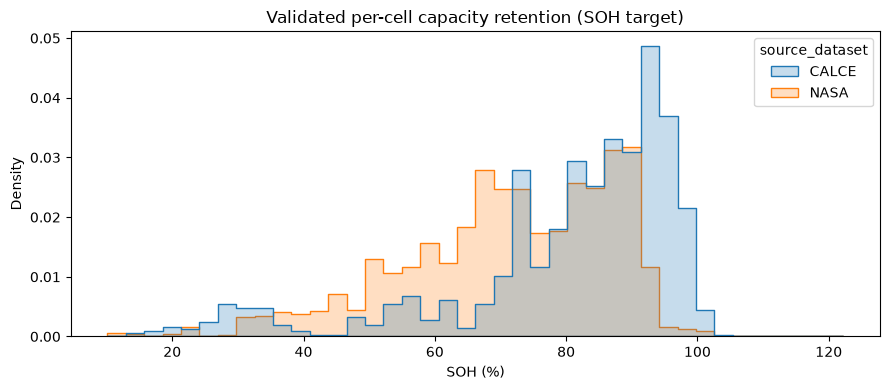

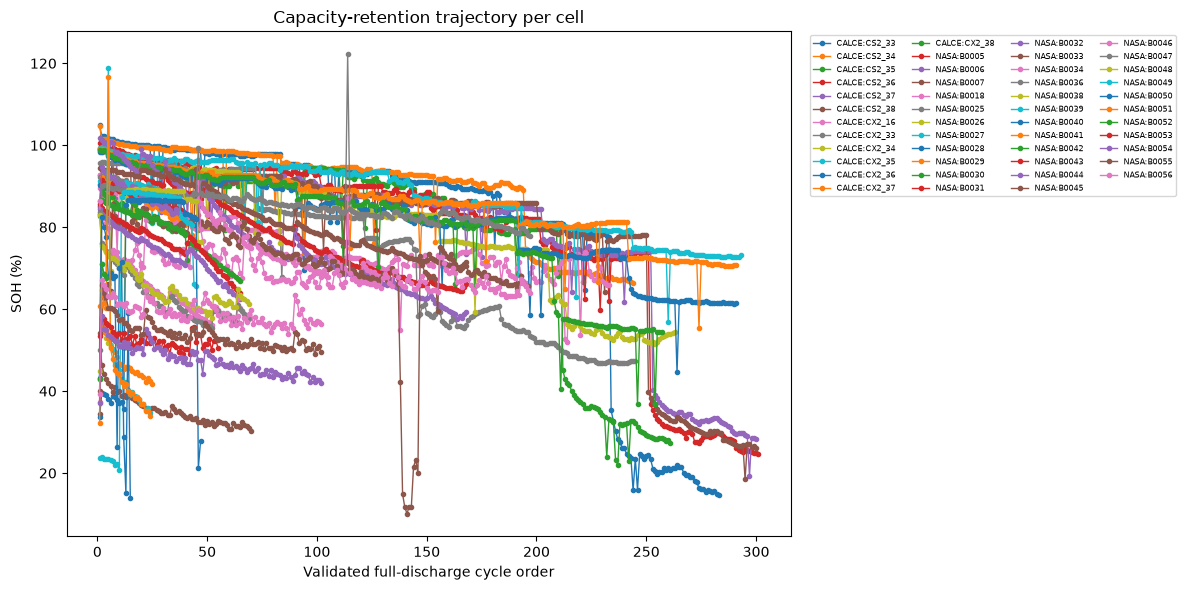

In [13]:
all_cycles = pd.concat([nasa_cycles, calce_cycles], ignore_index=True, sort=False)
all_cycles["cycle_start_time"] = pd.to_datetime(all_cycles["cycle_start_time"], errors="coerce")
all_cycles = all_cycles.sort_values(["source_dataset", "entity_id", "cycle_order"]).reset_index(drop=True)

calce_scale_rows = []
for cell, g in all_cycles[all_cycles.source_dataset.eq("CALCE")].groupby("entity_id"):
    family = "CS2" if cell.startswith("CS2") else "CX2"
    nominal = CALCE_NOMINAL_AH[family]
    vals = g["measured_discharge_capacity_Ah"].dropna()
    calce_scale_rows.append({"cell_id": cell, "family": family, "nominal_capacity_Ah": nominal,
        "cycles": len(vals), "first_capacity_Ah": vals.iloc[0] if len(vals) else np.nan,
        "median_capacity_Ah": vals.median() if len(vals) else np.nan,
        "last_capacity_Ah": vals.iloc[-1] if len(vals) else np.nan,
        "median_over_nominal": vals.median()/nominal if len(vals) else np.nan})
calce_scale_audit = pd.DataFrame(calce_scale_rows)
display(calce_scale_audit)
calce_scale_audit.to_csv(AUDIT_DIR / "calce_nominal_capacity_scale_audit.csv", index=False)

all_cycles = all_cycles.sort_values(["source_dataset", "entity_id", "cycle_order"]).copy()
all_cycles["soh_pct"] = 100.0 * all_cycles["measured_discharge_capacity_Ah"] / all_cycles["nominal_capacity_Ah"]
all_cycles["soh_flag"] = np.select(
    [all_cycles["soh_pct"] > 130, all_cycles["soh_pct"] < 10],
    ["review_above_130pct", "review_below_10pct"], default="within_review_band")

cell_audit = all_cycles.groupby(["source_dataset", "entity_id"]).agg(
    cycles=("cycle_id", "count"),
    nominal_capacity_Ah=("nominal_capacity_Ah", "first"),
    median_capacity_Ah=("measured_discharge_capacity_Ah", "median"),
    last_capacity_Ah=("measured_discharge_capacity_Ah", "last"),
    soh_min_pct=("soh_pct", "min"), soh_median_pct=("soh_pct", "median"), soh_max_pct=("soh_pct", "max"),
    flagged_soh_cycles=("soh_flag", lambda s: int((s != "within_review_band").sum())),
).reset_index()
display(cell_audit)
cell_audit.to_csv(AUDIT_DIR / "cell_soh_audit.csv", index=False)

display(all_cycles.groupby("source_dataset").agg(cells=("entity_id", "nunique"), cycles=("cycle_id", "count"),
    capacity_min_Ah=("measured_discharge_capacity_Ah", "min"), capacity_median_Ah=("measured_discharge_capacity_Ah", "median"),
    capacity_max_Ah=("measured_discharge_capacity_Ah", "max"), soh_median_pct=("soh_pct", "median"), soh_max_pct=("soh_pct", "max")).reset_index())
plt.figure(figsize=(9, 4))
sns.histplot(data=all_cycles, x="soh_pct", hue="source_dataset", bins=40, element="step", stat="density", common_norm=False)
plt.title("Validated per-cell capacity retention (SOH target)"); plt.xlabel("SOH (%)"); plt.tight_layout(); plt.show()
plt.figure(figsize=(12, 6))
for (source, cell), g in all_cycles.groupby(["source_dataset", "entity_id"]):
    plt.plot(g["cycle_order"], g["soh_pct"], marker=".", linewidth=1, label=f"{source}:{cell}")
plt.xlabel("Validated full-discharge cycle order"); plt.ylabel("SOH (%)"); plt.title("Capacity-retention trajectory per cell")
plt.legend(fontsize=6, ncol=4, bbox_to_anchor=(1.02, 1), loc="upper left"); plt.tight_layout(); plt.show()

## 12. Cross-source EDA, capacity checks, and predictor distributions

,source_dataset,battery_family,cells,cycles,voltage_median_V,current_median_A,temperature_missing_pct,soh_median_pct
0,CALCE,CS2,6,1689,3.632406,1.099568,100.0,87.956266
1,CALCE,CX2,7,1873,3.567396,1.349443,100.0,82.630257
2,NASA,NASA_18650,34,2562,3.460134,1.989583,0.0,72.778342


source_dataset,CALCE,NASA


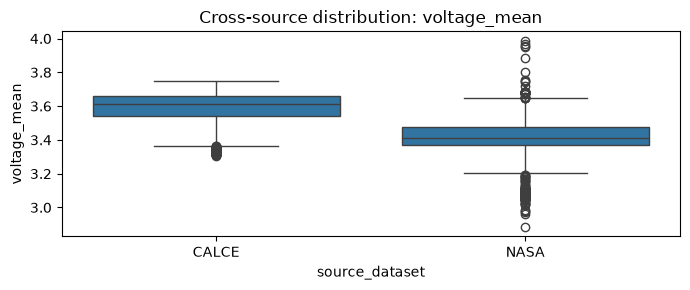

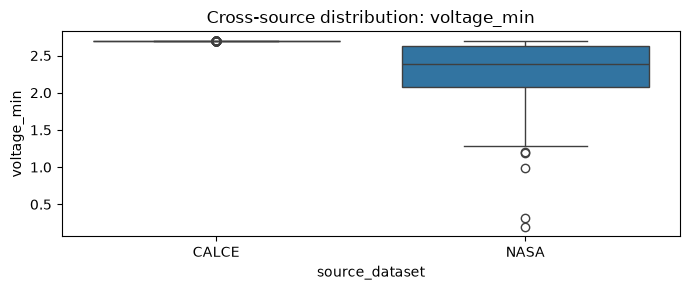

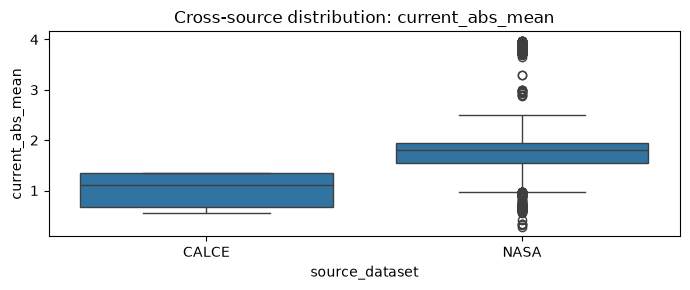

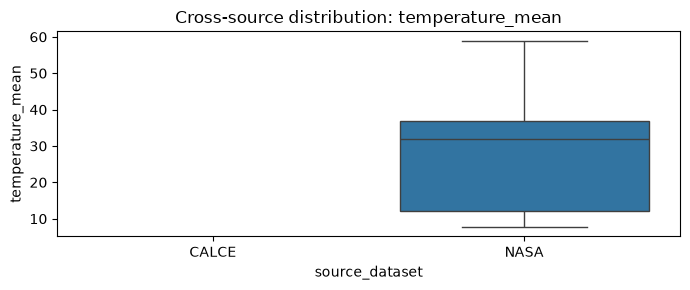

,cell_id,cycles_checked,median_integrated_Ah,median_counter_delta_Ah,median_counter_ratio
0,CS2_33,283,1.001285,1.001287,1.000001
1,CS2_34,244,1.032102,1.032077,1.000000
2,CS2_35,261,0.989474,0.989461,0.999998
3,CS2_36,301,0.935018,0.935020,1.000002
4,CS2_37,300,0.941230,0.941232,0.999999
5,CS2_38,300,0.946361,0.946359,1.000000
6,CX2_16,233,0.985942,0.985940,1.000001
7,CX2_33,245,1.044547,1.044552,1.000001
8,CX2_34,263,1.123659,1.123635,0.999998
9,CX2_35,293,1.167250,1.167235,1.000000


In [14]:
display(all_cycles.groupby(["source_dataset", "battery_family"]).agg(
    cells=("entity_id", "nunique"), cycles=("cycle_id", "count"),
    voltage_median_V=("voltage_median", "median"), current_median_A=("current_abs_median", "median"),
    temperature_missing_pct=("temperature_mean", lambda s: 100*s.isna().mean()),
    soh_median_pct=("soh_pct", "median")).reset_index())

eda_features = [c for c in FEATURE_COLUMNS if c in all_cycles.columns and c != "cycle_order"]
display(all_cycles.groupby("source_dataset")[eda_features].median(numeric_only=True).T)
for feature in ["voltage_mean", "voltage_min", "current_abs_mean", "temperature_mean"]:
    if feature in all_cycles.columns:
        plt.figure(figsize=(7, 3))
        sns.boxplot(data=all_cycles, x="source_dataset", y=feature)
        plt.title(f"Cross-source distribution: {feature}"); plt.tight_layout(); plt.show()

corr_cols = [c for c in FEATURE_COLUMNS if c in all_cycles.columns and all_cycles[c].notna().sum() > 3]
if len(corr_cols) > 1:
    plt.figure(figsize=(10, 7))
    sns.heatmap(all_cycles[corr_cols].corr(), cmap="coolwarm", center=0, annot=False)
    plt.title("Model-predictor correlation (capacity-derived columns excluded)"); plt.tight_layout(); plt.show()

if calce_capacity_checks:
    counter_audit = pd.DataFrame(calce_capacity_checks)
    display(counter_audit.groupby("cell_id").agg(
        cycles_checked=("integrated_Ah", "count"), median_integrated_Ah=("integrated_Ah", "median"),
        median_counter_delta_Ah=("counter_delta_Ah", "median"), median_counter_ratio=("counter_to_integrated_ratio", "median")
    ).reset_index())

## 13. Strict export gate — do not bypass a failed check

In [15]:
checks = []
def add_check(name, passed, detail):
    checks.append({"check": name, "passed": bool(passed), "detail": str(detail)})

nasa_cells_found = sorted(nasa_inventory.cell_id.unique().tolist())
calce_cells_found = sorted(calce_cells)
nasa_valid_cells = sorted(nasa_cycles.entity_id.unique().tolist())
calce_valid_cells = sorted(calce_cycles.entity_id.unique().tolist())

add_check("expected_NASA_file_count", len(nasa_cells_found) == EXPECTED_NASA_CELLS, f"found={len(nasa_cells_found)} expected={EXPECTED_NASA_CELLS}")
add_check("expected_CALCE_cell_folder_count", len(calce_cells_found) == EXPECTED_CALCE_CELLS, f"found={len(calce_cells_found)} expected={EXPECTED_CALCE_CELLS}")
add_check("all_NASA_cells_have_valid_cycles", set(nasa_cells_found).issubset(set(nasa_valid_cells)), f"missing={sorted(set(nasa_cells_found)-set(nasa_valid_cells))}")
add_check("all_CALCE_cells_have_valid_cycles", set(calce_cells_found).issubset(set(calce_valid_cells)), f"missing={sorted(set(calce_cells_found)-set(calce_valid_cells))}")
add_check("no_conflicting_duplicate_NASA_files", len(nasa_conflicts) == 0, f"conflicts={len(nasa_conflicts)}")
add_check("no_conflicting_CALCE_duplicate_cycle_starts", len(conflict_rows) == 0, f"conflicts={len(conflict_rows)}")
add_check("no_CALCE_parse_errors", len(calce_parse_errors) == 0, f"parse_errors={len(calce_parse_errors)}")
add_check("no_NASA_parse_errors", len(nasa_parse_errors) == 0, f"parse_errors={len(nasa_parse_errors)}")
add_check("every_cell_has_at_least_2_cycles", bool((cell_audit.cycles >= 2).all()), f"minimum_cycles={cell_audit.cycles.min()}")
add_check("all_capacities_positive_and_finite", bool(np.isfinite(all_cycles.measured_discharge_capacity_Ah).all() and (all_cycles.measured_discharge_capacity_Ah > 0).all()), "all cycle capacities must be finite and >0")
add_check("SOH_finite_positive", bool(np.isfinite(all_cycles.soh_pct).all() and (all_cycles.soh_pct > 0).all()), "all SOH labels must be finite and >0")
add_check("no_extreme_SOH_outliers", bool((all_cycles.soh_pct <= 130).all() and (all_cycles.soh_pct >= 10).all()), f"SOH range={all_cycles.soh_pct.min():.2f}..{all_cycles.soh_pct.max():.2f}; threshold 10..130")
add_check("CALCE_capacity_scale_matches_known_ratings", bool(((calce_scale_audit.median_over_nominal >= 0.25) & (calce_scale_audit.median_over_nominal <= 1.30)).all()), "CALCE median capacity / published nominal rating must be 0.25..1.30")
add_check("NASA_capacity_scale_matches_2Ah_rating", bool(((nasa_cycles.measured_discharge_capacity_Ah / NASA_NOMINAL_AH >= 0.10) & (nasa_cycles.measured_discharge_capacity_Ah / NASA_NOMINAL_AH <= 1.30)).all()), "NASA full-discharge capacity / 2.0 Ah rating must be 0.10..1.30")
add_check("CALCE_cycle_capacity_physical_range", bool((calce_cycles.measured_discharge_capacity_Ah <= calce_cycles.entity_id.map(lambda c: CALCE_NOMINAL_AH['CS2' if c.startswith('CS2') else 'CX2']*1.50)).all()), "each CALCE cycle must be <= 1.5 x its family rating")
add_check("no_duplicate_source_cell_cycle_rows", not all_cycles.duplicated(["source_dataset", "entity_id", "cycle_id"]).any(), "unique key source_dataset + entity_id + cycle_id")
add_check("exact_expected_cell_total", all_cycles[["source_dataset", "entity_id"]].drop_duplicates().shape[0] == EXPECTED_TOTAL_CELLS, f"found={all_cycles[['source_dataset','entity_id']].drop_duplicates().shape[0]} expected={EXPECTED_TOTAL_CELLS}")

checks_df = pd.DataFrame(checks)
display(checks_df)
checks_df.to_csv(AUDIT_DIR / "export_gate_checks.csv", index=False)
if not checks_df.passed.all():
    failed = checks_df.loc[~checks_df.passed]
    raise RuntimeError("EXPORT BLOCKED: validation gates failed. Review analysis_outputs/ and resolve the failures.\n" + failed.to_string(index=False))
print("All data-quality gates passed. Export is permitted.")

,check,passed,detail
0,expected_NASA_file_count,True,found=34 expected=34
1,expected_CALCE_cell_folder_count,True,found=13 expected=13
2,all_NASA_cells_have_valid_cycles,True,missing=[]
3,all_CALCE_cells_have_valid_cycles,True,missing=[]
4,no_conflicting_duplicate_NASA_files,True,conflicts=0
5,no_conflicting_CALCE_duplicate_cycle_starts,True,conflicts=0
6,no_CALCE_parse_errors,True,parse_errors=0
7,no_NASA_parse_errors,True,parse_errors=0
8,every_cell_has_at_least_2_cycles,True,minimum_cycles=4
9,all_capacities_positive_and_finite,True,all cycle capacities must be finite and >0


All data-quality gates passed. Export is permitted.


## 14. Prepare model-ready unified schema and explicitly isolate leakage columns

In [16]:
rename_map = {
    "voltage_mean": "voltage_mean_V", "voltage_std": "voltage_std_V",
    "voltage_min": "voltage_min_V", "voltage_max": "voltage_max_V",
    "voltage_median": "voltage_median_V", "voltage_q10": "voltage_q10_V", "voltage_q90": "voltage_q90_V",
    "current_abs_mean": "current_abs_mean_A", "current_abs_std": "current_abs_std_A",
    "current_abs_median": "current_abs_median_A",
    "temperature_mean": "temperature_mean_C", "temperature_std": "temperature_std_C",
    "temperature_min": "temperature_min_C", "temperature_max": "temperature_max_C",
}
model_df = all_cycles.rename(columns=rename_map).copy()
for col in FEATURE_COLUMNS:
    if col not in model_df.columns:
        model_df[col] = np.nan
model_df["battery_family"] = model_df["battery_family"].fillna("NASA_18650")

keep_columns = [
    "source_dataset", "battery_family", "entity_id", "cycle_id", "raw_cycle_index",
    "cycle_order", "cycle_start_time", "cycle_end_time", "source_file", "source_sheet",
    "measured_discharge_capacity_Ah", "nominal_capacity_Ah", "soh_pct", "soh_flag",
    "capacity_integration_Ah", "capacity_counter_delta_Ah",
    "voltage_min_check_V", "voltage_max_check_V", "discharge_sample_count", "discharge_duration_s",
] + FEATURE_COLUMNS
keep_columns = list(dict.fromkeys(c for c in keep_columns if c in model_df.columns))
model_df = model_df[keep_columns].sort_values(["source_dataset", "entity_id", "cycle_order"]).reset_index(drop=True)

MODEL_FEATURE_COLUMNS = FEATURE_COLUMNS.copy()
MODEL_CATEGORICAL_COLUMNS = CATEGORICAL_COLUMNS.copy()
MODEL_TARGET_COLUMN = "soh_pct"
MODEL_GROUP_COLUMN = "entity_id"
print("Predictors:", MODEL_FEATURE_COLUMNS)
print("Categorical predictors:", MODEL_CATEGORICAL_COLUMNS)
print("Target:", MODEL_TARGET_COLUMN, "| Group for LOCO:", MODEL_GROUP_COLUMN)
print("Forbidden leakage/audit fields:", [c for c in keep_columns if c not in MODEL_FEATURE_COLUMNS + MODEL_CATEGORICAL_COLUMNS + [MODEL_TARGET_COLUMN]])
display(model_df.head())

with open(AUDIT_DIR / "model_schema.json", "w") as f:
    json.dump({"feature_columns": MODEL_FEATURE_COLUMNS, "categorical_columns": MODEL_CATEGORICAL_COLUMNS,
               "target_column": MODEL_TARGET_COLUMN, "group_column": MODEL_GROUP_COLUMN,
               "soh_definition": "100 * discharge_capacity_Ah / published_nominal_capacity_Ah",
               "nominal_capacity_Ah": {"NASA": 2.0, "CALCE_CS2": 1.1, "CALCE_CX2": 1.35}}, f, indent=2)

Predictors: ['cycle_order', 'voltage_mean_V', 'voltage_std_V', 'voltage_min_V', 'voltage_max_V', 'voltage_median_V', 'voltage_q10_V', 'voltage_q90_V', 'current_abs_mean_A', 'current_abs_std_A', 'current_abs_median_A', 'temperature_mean_C', 'temperature_std_C', 'temperature_min_C', 'temperature_max_C']
Categorical predictors: ['source_dataset', 'battery_family']
Target: soh_pct | Group for LOCO: entity_id
Forbidden leakage/audit fields: ['entity_id', 'cycle_id', 'raw_cycle_index', 'cycle_start_time', 'cycle_end_time', 'source_file', 'source_sheet', 'measured_discharge_capacity_Ah', 'nominal_capacity_Ah', 'soh_flag', 'capacity_integration_Ah', 'capacity_counter_delta_Ah', 'voltage_min_check_V', 'voltage_max_check_V', 'discharge_sample_count', 'discharge_duration_s']


,source_dataset,battery_family,entity_id,cycle_id,raw_cycle_index,cycle_order,cycle_start_time,cycle_end_time,source_file,source_sheet,measured_discharge_capacity_Ah,nominal_capacity_Ah,soh_pct,soh_flag,capacity_integration_Ah,capacity_counter_delta_Ah,voltage_min_check_V,voltage_max_check_V,discharge_sample_count,discharge_duration_s,voltage_mean_V,voltage_std_V,voltage_min_V,voltage_max_V,voltage_median_V,voltage_q10_V,voltage_q90_V,current_abs_mean_A,current_abs_std_A,current_abs_median_A,temperature_mean_C,temperature_std_C,temperature_min_C,temperature_max_C
0,CALCE,CS2,CS2_33,CALCE:CS2_33:0001,1,1,2010-08-18 13:34:27,2010-08-18 15:40:23,calce/CS2_33/CS2_33/CS2_33_8_19_10.xlsx,Channel_1-006,1.154718,1.1,104.974408,within_review_band,1.154718,1.154736,2.699699,4.107244,255,7555.841417,3.734260,0.203324,2.699699,4.107244,3.719598,3.564216,3.985685,0.550169,0.000116,0.550173,NaN,NaN,NaN,NaN
1,CALCE,CS2,CS2_33,CALCE:CS2_33:0002,1,2,2010-08-31 16:00:07,2010-08-31 18:02:41,calce/CS2_33/CS2_33/CS2_33_9_7_10.xlsx,Channel_1-006,1.123849,1.1,102.168049,within_review_band,1.123849,1.123819,2.699861,4.109025,249,7353.888816,3.736413,0.211212,2.699861,4.109025,3.725754,3.565900,3.991776,0.550164,0.000118,0.550173,NaN,NaN,NaN,NaN
2,CALCE,CS2,CS2_33,CALCE:CS2_33:0003,2,3,2010-08-31 20:35:59,2010-08-31 22:38:32,calce/CS2_33/CS2_33/CS2_33_9_7_10.xlsx,Channel_1-006,1.123591,1.1,102.144664,within_review_band,1.123591,1.123597,2.699861,4.111294,249,7352.478579,3.741824,0.209394,2.699861,4.111294,3.729641,3.574551,3.996182,0.550144,0.000108,0.550173,NaN,NaN,NaN,NaN
3,CALCE,CS2,CS2_33,CALCE:CS2_33:0004,3,4,2010-09-01 01:09:55,2010-09-01 03:12:25,calce/CS2_33/CS2_33/CS2_33_9_7_10.xlsx,Channel_1-006,1.123349,1.1,102.122662,within_review_band,1.123349,1.123326,2.699537,4.113723,249,7350.516938,3.744210,0.210013,2.699537,4.113723,3.731747,3.577013,3.999260,0.550172,0.000123,0.550173,NaN,NaN,NaN,NaN
4,CALCE,CS2,CS2_33,CALCE:CS2_33:0005,4,5,2010-09-01 05:44:31,2010-09-01 07:46:33,calce/CS2_33/CS2_33/CS2_33_9_7_10.xlsx,Channel_1-006,1.118982,1.1,101.725632,within_review_band,1.118982,1.118963,2.699861,4.109836,248,7322.125133,3.737130,0.211409,2.699861,4.109836,3.725511,3.567374,3.993623,0.550161,0.000120,0.550173,NaN,NaN,NaN,NaN


## 15. Export genuine Parquet atomically and validate its round-trip

In [17]:
tmp_path = OUTPUT_PARQUET.with_name("unified.tmp.parquet")
if tmp_path.exists(): tmp_path.unlink()
export_table = pa.Table.from_pandas(model_df, preserve_index=False)
pq.write_table(export_table, tmp_path, compression="zstd", compression_level=6,
               use_dictionary=True, write_statistics=True)

candidate_pf = pq.ParquetFile(tmp_path)
assert candidate_pf.metadata.num_rows == len(model_df)
roundtrip = candidate_pf.read().to_pandas()
assert set(roundtrip["source_dataset"].dropna().unique()) == {"NASA", "CALCE"}
assert roundtrip[["source_dataset", "entity_id", "cycle_id", "soh_pct"]].notna().all().all()
assert not roundtrip.duplicated(["source_dataset", "entity_id", "cycle_id"]).any()
assert np.isfinite(roundtrip["soh_pct"]).all()
assert roundtrip["soh_pct"].between(10, 130).all()
assert roundtrip[["source_dataset", "entity_id"]].drop_duplicates().shape[0] == EXPECTED_TOTAL_CELLS

tmp_path.replace(OUTPUT_PARQUET)
print("SUCCESS — verified Parquet written to:", OUTPUT_PARQUET)
print("Rows:", len(roundtrip), "| cells:", roundtrip[["source_dataset", "entity_id"]].drop_duplicates().shape[0])
print("File size (MiB):", round(OUTPUT_PARQUET.stat().st_size / 2**20, 3))
display(roundtrip.groupby("source_dataset").agg(
    cells=("entity_id", "nunique"), cycles=("cycle_id", "count"),
    capacity_min_Ah=("measured_discharge_capacity_Ah", "min"),
    capacity_median_Ah=("measured_discharge_capacity_Ah", "median"),
    capacity_max_Ah=("measured_discharge_capacity_Ah", "max"),
    soh_min_pct=("soh_pct", "min"), soh_median_pct=("soh_pct", "median"), soh_max_pct=("soh_pct", "max")
).reset_index())

SUCCESS — verified Parquet written to: /home/raj/Documents/Projects/PBL/data/unified.parquet
Rows: 6124 | cells: 47
File size (MiB): 0.848


,source_dataset,cells,cycles,capacity_min_Ah,capacity_median_Ah,capacity_max_Ah,soh_min_pct,soh_median_pct,soh_max_pct
0,CALCE,13,3562,0.160905,1.016700,1.344048,14.627750,85.617165,104.974408
1,NASA,34,2562,0.202563,1.455567,2.444062,10.128165,72.778342,122.203122


## 16. Final handoff — inspect once before starting baseline training

In [18]:
final_pf = pq.ParquetFile(OUTPUT_PARQUET)
final_df = final_pf.read().to_pandas()
print("Parquet physical format:", final_pf.metadata.format_version)
print("Parquet rows:", final_pf.metadata.num_rows)
print("Unique cells:", final_df[["source_dataset", "entity_id"]].drop_duplicates().shape[0])
print("Unique cycles:", final_df[["source_dataset", "entity_id", "cycle_id"]].drop_duplicates().shape[0])
print("Sources:", sorted(final_df.source_dataset.unique()))
print("Model input columns:", MODEL_FEATURE_COLUMNS + MODEL_CATEGORICAL_COLUMNS)
print("Target:", MODEL_TARGET_COLUMN)
print("Group split column:", MODEL_GROUP_COLUMN)
print("All audit outputs:", AUDIT_DIR)

print("Do not use random row-wise train/test splitting; keep all cycles from a cell together (LOCO / GroupKFold).")

Parquet physical format: 2.6
Parquet rows: 6124
Unique cells: 47
Unique cycles: 6124
Sources: ['CALCE', 'NASA']
Model input columns: ['cycle_order', 'voltage_mean_V', 'voltage_std_V', 'voltage_min_V', 'voltage_max_V', 'voltage_median_V', 'voltage_q10_V', 'voltage_q90_V', 'current_abs_mean_A', 'current_abs_std_A', 'current_abs_median_A', 'temperature_mean_C', 'temperature_std_C', 'temperature_min_C', 'temperature_max_C', 'source_dataset', 'battery_family']
Target: soh_pct
Group split column: entity_id
All audit outputs: /home/raj/Documents/Projects/PBL/data/analysis_outputs
Do not use random row-wise train/test splitting; keep all cycles from a cell together (LOCO / GroupKFold).
